DIPLOMADO EN INVERSIONES FINANCIERAS
PROYECTO GESTIÓN DE INVERSIONES CON PYTHON
PROFESOR ANDRÉS MEDINA
ALUMNO DANIEL MENARES

A1- SELECCION INICIAL DE PORTAFOLIO DIVERSIFICADO

In [235]:
!pip install arch


In [236]:
# LIBRERIAS UTILIZADAS EN EL PROYECTO Y SU FUNCION #

import yfinance as yf                # DESCARGA DATOS FINANCIEROS DE YAHOO FINANCE
import numpy as np                   # REALIZA CÁLCULOS MATEMÁTICOS Y OPERACIONES CON MATRICES
import pandas as pd                  # MANEJA Y ANALIZA DATOS EN TABLAS ESTRUCTURADAS
import seaborn as sns                # CREA GRÁFICOS ESTADÍSTICOS Y PERSONALIZADOS
import warnings                      # CONTROLA Y AJUSTA MENSAJES DE ADVERTENCIA EN EL CÓDIGO
import matplotlib.pyplot as plt      # GENERA GRÁFICOS BÁSICOS EN 2D
from scipy.optimize import minimize  # RESUELVE PROBLEMAS DE OPTIMIZACIÓN MATEMÁTICA
from scipy.stats import skew, kurtosis # CALCULA ASIMETRÍA (FORMA) Y CURTOSIS (PICOS) DE UNA DISTRIBUCIÓN
from arch import arch_model          # MODELO GARCH PARA ESTIMAR CÓMO CAMBIA LA VOLATILIDAD EN EL TIEMPO
import os                            # PERMITE INTERACTUAR CON EL SISTEMA OPERATIVO
import contextlib                    # MANEJA CONTEXTOS DE EJECUCIÓN DE FORMA SEGURA Y EFICIENTE
from sklearn.preprocessing import StandardScaler # NORMALIZA LOS DATOS PARA MEJORAR EL DESEMPEÑO DEL MODELO
from sklearn.decomposition import PCA # REDUCE LA DIMENSIONALIDAD DE LOS DATOS PARA MEJORAR SU INTERPRETACIÓN
from sklearn.cluster import KMeans    # REALIZA AGRUPAMIENTOS DE DATOS EN GRUPOS (CLUSTERING)
from sklearn.cluster import DBSCAN    # REALIZA AGRUPAMIENTOS BASADOS EN DENSIDAD DE DATOS
import scipy.cluster.hierarchy as shc # GENERA AGRUPAMIENTOS JERÁRQUICOS PARA ANALIZAR RELACIONES ENTRE DATOS
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf # GENERA GRÁFICOS DE AUTOCORRELACIÓN (ACF) Y AUTOCORRELACIÓN PARCIAL (PACF)
from sklearn.model_selection import train_test_split # DIVIDE LOS DATOS EN CONJUNTOS DE ENTRENAMIENTO Y PRUEBA
from sklearn.svm import SVR           # IMPLEMENTA MÁQUINAS DE SOPORTE VECTORIAL PARA REGRESIÓN
from sklearn.ensemble import RandomForestRegressor # IMPLEMENTA UN MODELO DE BOSQUES ALEATORIOS PARA REGRESIÓN
from sklearn.metrics import mean_squared_error # EVALÚA LA PRECISIÓN DEL MODELO CALCULANDO EL ERROR CUADRÁTICO MEDIO
import cvxpy as cv                    # REALIZA OPTIMIZACIÓN CON PROGRAMACIÓN LINEAL Y CONVEXA
import matplotlib.dates as mdates     # MANEJA FECHAS Y SU FORMATEO EN GRÁFICOS









A 1.1 PORTAFOLIO INICIAL DE 50 ACCIONES

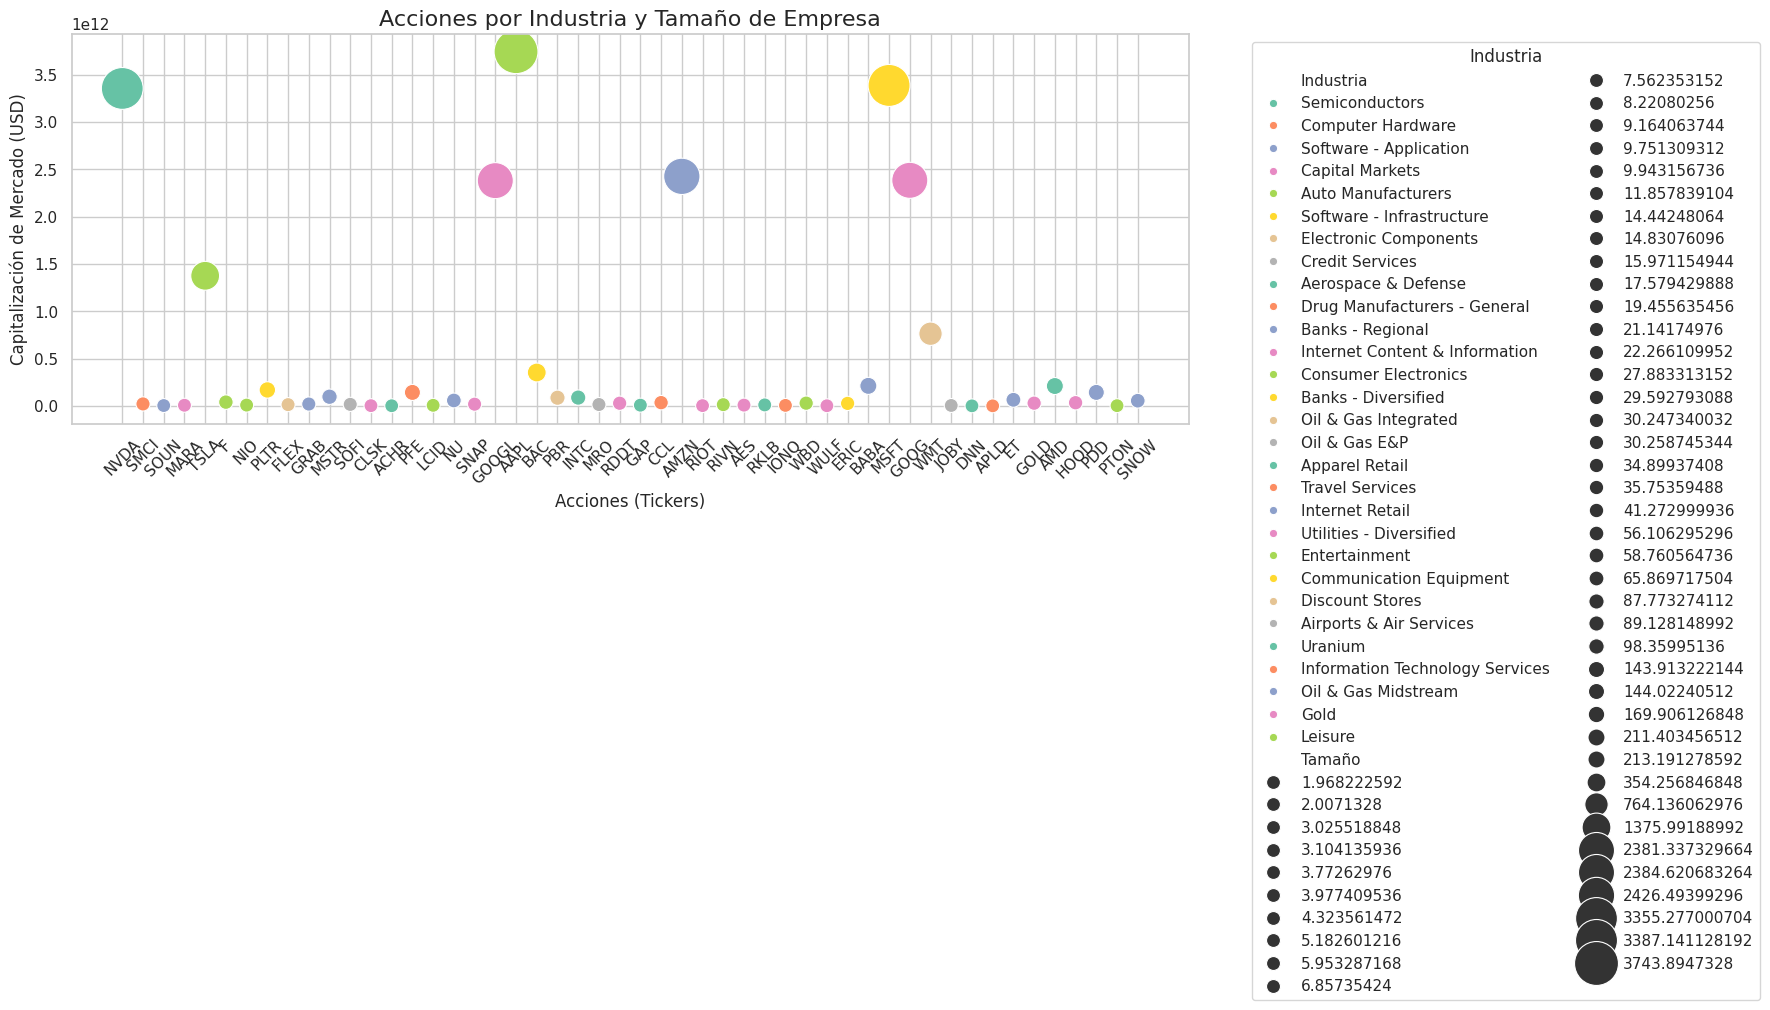

In [ ]:
# LISTA DE ACCIONES
tickers = ["NVDA", "SMCI", "SOUN", "MARA", "TSLA", "F", "NIO", "PLTR", "FLEX", "GRAB",                       # TICKERS DE LAS ACCIONES A ANALIZAR
           "MSTR", "SOFI", "CLSK", "ACHR", "PFE", "LCID", "NU", "SNAP", "GOOGL", "AAPL",
           "BAC", "PBR", "INTC", "MRO", "RDDT", "GAP", "CCL", "AMZN", "RIOT", "RIVN",
           "AES", "RKLB", "IONQ", "WBD", "WULF", "ERIC", "BABA", "MSFT", "GOOG", "WMT",
           "JOBY", "DNN", "APLD", "ET", "GOLD", "AMD", "HOOD", "PDD", "PTON", "SNOW"]

# INICIALIZAR DICCIONARIOS PARA ALMACENAR INDUSTRIAS Y CAPITALIZACIONES DE MERCADO
industry_info = {}                                                                                           # DICCIONARIO PARA GUARDAR LA INDUSTRIA DE CADA ACCIÓN
market_cap_data = {}                                                                                         # DICCIONARIO PARA GUARDAR LA CAPITALIZACIÓN DE MERCADO DE CADA ACCIÓN

# DESCARGAR DATOS PARA CADA TICKER
for ticker in tickers:                                                                                       # ITERAR SOBRE CADA TICKER EN LA LISTA
    try:
        stock_info = yf.Ticker(ticker).info                                                                  # OBTENER INFORMACIÓN DE LA ACCIÓN DESDE YAHOO FINANCE
        industry = stock_info.get("industry", "Desconocido")                                                 # OBTENER LA INDUSTRIA O ASIGNAR "DESCONOCIDO" SI NO HAY DATOS
        market_cap = stock_info.get("marketCap", 0)                                                          # OBTENER LA CAPITALIZACIÓN DE MERCADO O ASIGNAR 0 SI NO HAY DATOS

        # GUARDAR INFORMACIÓN SI ES VÁLIDA
        industry_info[ticker] = industry                                                                     # GUARDAR LA INDUSTRIA EN EL DICCIONARIO
        market_cap_data[ticker] = market_cap                                                                 # GUARDAR LA CAPITALIZACIÓN DE MERCADO EN EL DICCIONARIO

    except Exception as e:                                                                                   # MANEJAR ERRORES SI OCURREN
        print(f"Error al procesar {ticker}: {e}")                                                            # IMPRIMIR EL ERROR PARA SABER QUÉ PASÓ
        industry_info[ticker] = "Desconocido"                                                                # ASIGNAR "DESCONOCIDO" A LA INDUSTRIA SI HAY ERROR
        market_cap_data[ticker] = 0                                                                          # ASIGNAR 0 A LA CAPITALIZACIÓN DE MERCADO SI HAY ERROR

# FILTRAR SOLO TICKERS CON DATOS VÁLIDOS
valid_tickers = [ticker for ticker in tickers if market_cap_data[ticker] > 0]                                # INCLUIR SOLO TICKERS CON CAPITALIZACIÓN MAYOR A 0

# CREAR DATAFRAME PARA GRAFICAR
data = pd.DataFrame({                                                                                        # CREAR UNA TABLA CON LOS DATOS FILTRADOS
    "Ticker": valid_tickers,  # TICKERS VÁLIDOS
    "Industria": [industry_info[ticker] for ticker in valid_tickers],                                        # INDUSTRIAS ASOCIADAS A LOS TICKERS
    "Capitalización de Mercado (USD)": [market_cap_data[ticker] for ticker in valid_tickers]                 # CAPITALIZACIÓN DE MERCADO EN USD
})

# ASIGNAR TAMAÑO RELATIVO DE LOS PUNTOS BASADO EN LA CAPITALIZACIÓN DE MERCADO
data["Tamaño"] = data["Capitalización de Mercado (USD)"] / 1e9                                               # ESCALAR A MILES DE MILLONES PARA EL GRÁFICO

# CONFIGURAR ESTILO DE SEABORN
sns.set(style="whitegrid")                                                                                   # APLICAR UN ESTILO DE CUADRÍCULA BLANCA PARA EL GRÁFICO

# CREAR EL GRÁFICO DE DISPERSIÓN
plt.figure(figsize=(18, 8))                                                                                  # ESTABLECER EL TAMAÑO DE LA FIGURA
scatter = sns.scatterplot(                                                                                   # CREAR UN GRÁFICO DE DISPERSIÓN
    data=data,                                                                                               # USAR EL DATAFRAME CON LOS DATOS
    x="Ticker",                                                                                              # TICKERS EN EL EJE X
    y="Capitalización de Mercado (USD)",                                                                     # CAPITALIZACIÓN DE MERCADO EN EL EJE Y
    hue="Industria",                                                                                         # COLOR DE LOS PUNTOS BASADO EN LA INDUSTRIA
    size="Tamaño",                                                                                           # TAMAÑO DE LOS PUNTOS BASADO EN LA CAPITALIZACIÓN
    sizes=(100, 1000),                                                                                       # RANGO DE TAMAÑOS DE LOS PUNTOS (MÍNIMO Y MÁXIMO)
    palette="Set2",                                                                                          # PALETA DE COLORES PARA LAS INDUSTRIAS
    legend="full"                                                                                            # MOSTRAR LA LEYENDA COMPLETA
)

# CONFIGURAR ETIQUETAS Y TÍTULO
plt.title("Acciones por Industria y Tamaño de Empresa", fontsize=16)                                         # TÍTULO DEL GRÁFICO
plt.xlabel("Acciones (Tickers)", fontsize=12)                                                                # ETIQUETA DEL EJE X
plt.ylabel("Capitalización de Mercado (USD)", fontsize=12)                                                   # ETIQUETA DEL EJE Y
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Industria", ncol=2)                            # AJUSTAR LA LEYENDA AL LADO DERECHO
plt.xticks(rotation=45)                                                                                      # ROTAR LAS ETIQUETAS EN EL EJE X PARA MEJOR VISIBILIDAD
plt.grid(True)                                                                                               # MOSTRAR LA CUADRÍCULA EN EL GRÁFICO

# MOSTRAR EL GRÁFICO
plt.tight_layout()                                                                                           # AJUSTAR LOS MÁRGENES PARA QUE TODO QUEPA
plt.show()                                                                                                   # MOSTRAR EL GRÁFICO

PRECIOS DE LAS ACCIONES ELEGIDAS

In [203]:
### FUNCIONES UTILIZADAS ###
#sort                                 # ORDENA ALFABETICAMENTE LA LISTA DE TICKERS
#len                                  # CUENTA EL NUMERO TOTAL DE TICKERS EN LA LISTA
#yf.download                          # DESCARGA LOS DATOS HISTORICOS DE YAHOO FINANZAS
#resample                             # AGRUPA LOS DATOS EN INTERVALOS DE TIEMPO MENSUALES 'M' TOMANDO EL ULTIMO PRECIO DE CADA MES 'LAST'
#pct_change                           # CALCULA LOS CAMBIOS PORCENTUALES ENTRE PERIODOS CONSECUTIVOS
#dropna                               # ELIMINA LOS VALORES VACIOS
#fill_method=None                     # COMPLETA EL VACIO CON EL VALOR ANTERIOR

# 50 TIKERS DEL PORTAFOLIO INICIAL
tickers = ["NVDA", "SMCI", "SOUN", "MARA", "TSLA", "F", "NIO", "PLTR", "FLEX", "GRAB",
    "MSTR", "SOFI", "CLSK", "ACHR", "PFE", "LCID", "NU", "SNAP", "GOOGL", "AAPL",
    "BAC", "PBR", "INTC", "MRO", "RDDT", "GAP", "CCL", "AMZN", "RIOT", "RIVN",
    "AES", "RKLB", "IONQ", "WBD", "WULF", "ERIC", "BABA", "MSFT", "GOOG", "WMT",
    "JOBY", "DNN", "APLD", "ET", "GOLD", "AMD", "HOOD", "PDD", "PTON", "SNOW"]

# ORDENAR LOS TIKERS ALFABETICAMENTE
tickers.sort()

# GUARDAR EL TOTAL DE TICKERS
n = len(tickers)

start = '2019-01-01' # FECHA DE INICIO
end = '2024-12-05'   # FECHA DE TERMINO

# DESCARGAR LAS SERIES DE PRECIOS
data = yf.download(tickers, start = start, end = end)["Close"]

# AGRUPACION DE DATOS EN INTERVALOS MENSUALES
data = data.resample('ME').last()

# GENERA RETORNOS LOGARITMICOS Y ELIMINA VALORES VACIOS REPITIENDO EL VALOR ANTERIOR
returns = data.pct_change(fill_method=None).dropna()

[*********************100%***********************]  50 of 50 completed


CARACTERISTICAS DE LAS ACCIONES A ANALIZAR

A 1.2 VISUALIZACION DE PRECIOS DE CIERRE

<Figure size 1000x800 with 0 Axes>

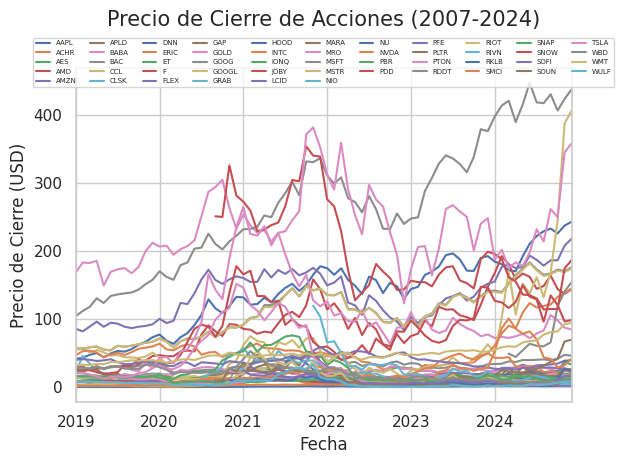

In [204]:

# VISUALIZACION DE CIERRE DE PRECIOS                                       ### FUNCIONES UTILIZADAS ###
fig = plt.figure(figsize=(10, 8))                                          # CREA UNA FIGURA DE TAMAÑO ESPECIFICO
data.plot()                                                                # GENERA EL GRAAFICO CON LOS DATOS DE LA VARIABLE 'DATA'
plt.title('Precio de Cierre de Acciones (2007-2024)', fontsize=15, pad=30) # AGREGA UN TITULO AL GRAFICO- - PAD AJUSTA LA DISTANCIA ENTRE EL TEXTO Y EL GRAFICO
plt.xlabel('Fecha', fontsize=12)                                           # GENERA TEXTO PARA EL EJE X - FONTSIZE CONTROLA EL TAMAÑO DEL TEXTO
plt.ylabel('Precio de Cierre (USD)', fontsize=12)                          # GENERA TEXTO PARA EL EJE Y - FONTSIZE CONTROLA EL TAMAÑO DEL TEXTO
plt.legend(tickers, loc='upper center', bbox_to_anchor=(0.5, 1.1), ncol=11, fontsize=5) # MUEVE LA LEYENDA A LA DERECHA - NCOL N° DE COLUMNAS QUE TENDRÁ LA LEYENDA
plt.grid(True)                                                             # ACTIVA UNA CUADRILLA AL FONDO DEL GRAFICO
plt.tight_layout()                                                         # AJUSTA AUTOMATICAMENTE EL GRAFICO PARA QUE NO SE SUPERPONGA
plt.show()                                                                 # MUESTRA EL GRAFICO EN LA PANTALLA


A 1.3 CALCULO DE RETORNOS Y VISUALZIACION

[*********************100%***********************]  50 of 50 completed


        count      mean       std       min       25%       50%       75%  \
Ticker                                                                      
RKLB    169.0  0.010123  0.046002 -0.096498 -0.015891  0.004242  0.026668   
IONQ    169.0  0.007397  0.058011 -0.144078 -0.031105  0.005420  0.041426   
RDDT    169.0  0.007302  0.055574 -0.157794 -0.024454 -0.000472  0.033181   
WULF    169.0  0.006179  0.067938 -0.148889 -0.042023  0.000000  0.050246   
MSTR    169.0  0.005673  0.063878 -0.193939 -0.037160 -0.001057  0.037889   
PLTR    169.0  0.005510  0.036378 -0.163850 -0.011254  0.002449  0.019874   
APLD    169.0  0.004551  0.084409 -0.266434 -0.048119  0.001318  0.052532   
PTON    169.0  0.004549  0.056507 -0.178747 -0.031974 -0.001167  0.034641   
SOFI    169.0  0.004265  0.030458 -0.110740 -0.013857  0.002635  0.021177   
TSLA    169.0  0.004066  0.041762 -0.131643 -0.019396  0.002086  0.025790   
HOOD    169.0  0.003852  0.038783 -0.183102 -0.014586  0.004839  0.023557   

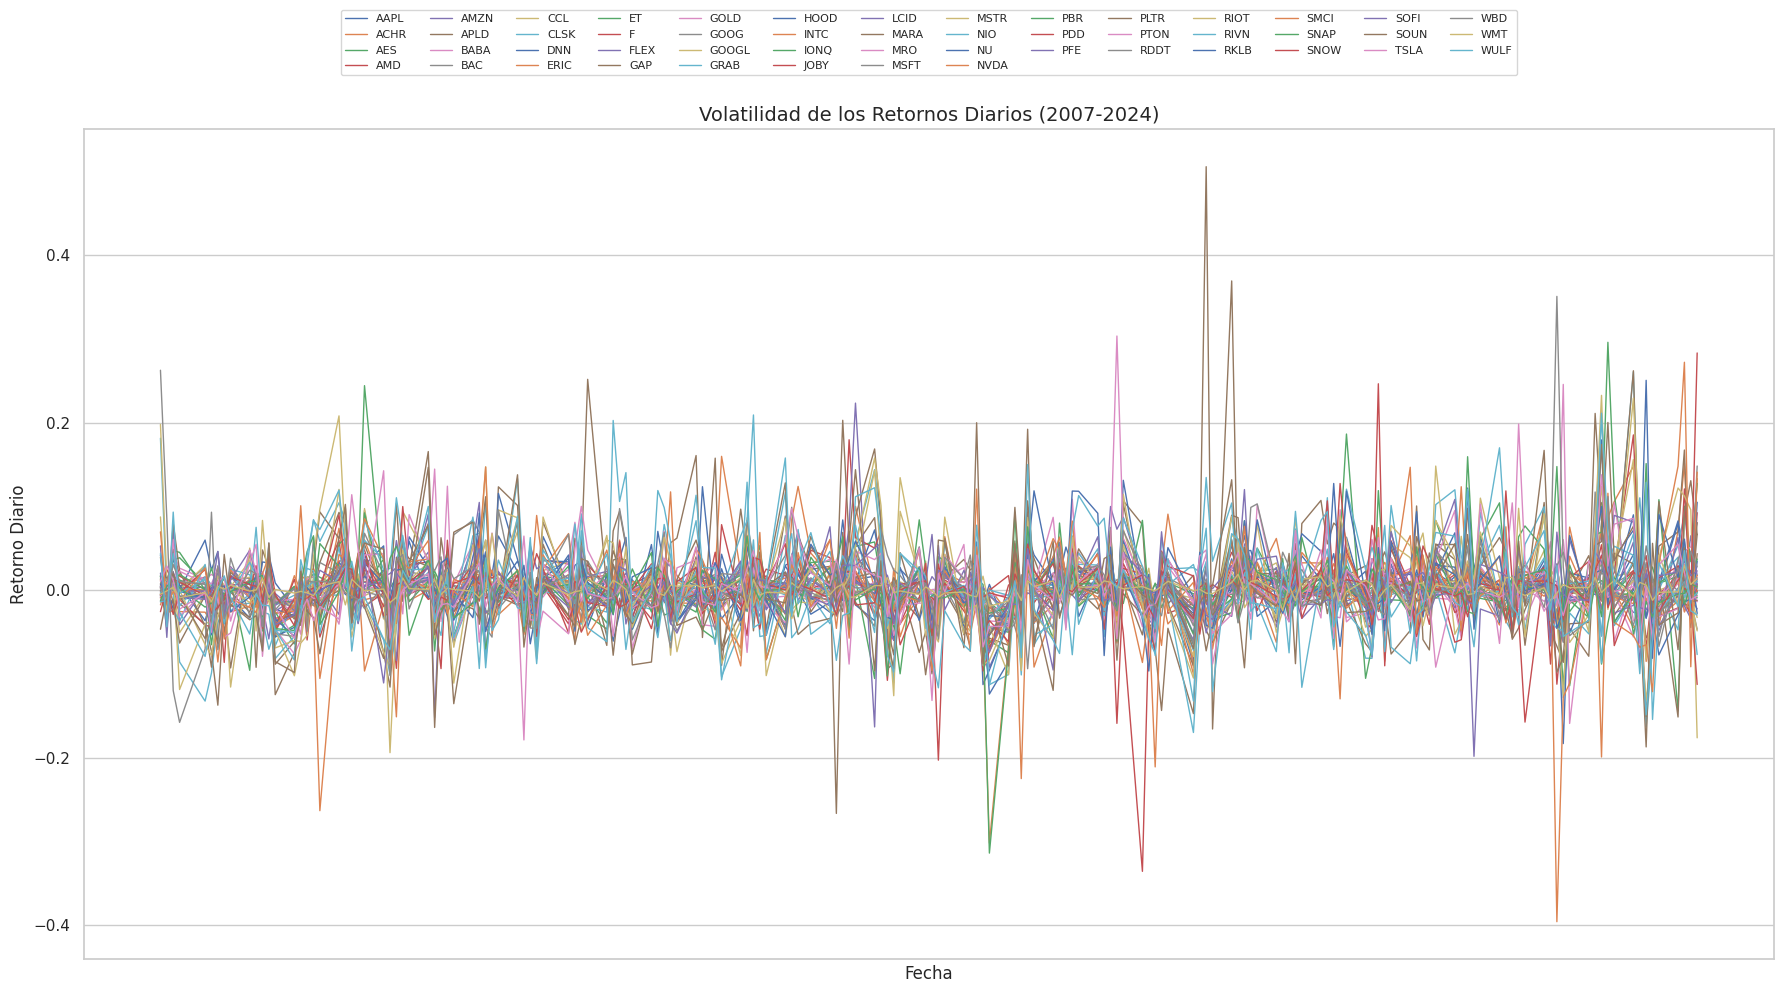

In [205]:

tickers = ["NVDA", "SMCI", "SOUN", "MARA", "TSLA", "F", "NIO", "PLTR", "FLEX", "GRAB",
           "MSTR", "SOFI", "CLSK", "ACHR", "PFE", "LCID", "NU", "SNAP", "GOOGL", "AAPL",
           "BAC", "PBR", "INTC", "MRO", "RDDT", "GAP", "CCL", "AMZN", "RIOT", "RIVN",
           "AES", "RKLB", "IONQ", "WBD", "WULF", "ERIC", "BABA", "MSFT", "GOOG", "WMT",
           "JOBY", "DNN", "APLD", "ET", "GOLD", "AMD", "HOOD", "PDD", "PTON", "SNOW"]

# FECHAS PARA DESCARGAR DATOS
start = '2019-01-01'  # FECHA DE INICIO DEL PERIODO DE ANÁLISIS
end = '2024-12-05'    # FECHA DE TERMINO DEL PERIODO DE ANÁLISIS

# DESCARGAR DATOS
# DESCARGA LOS PRECIOS DE CIERRE DE LAS ACCIONES DESDE YAHOO FINANCE
data = yf.download(tickers, start=start, end=end)['Close']

# CALCULAR RETORNOS LOGARÍTMICOS
# CALCULAR LOS CAMBIOS RELATIVOS ENTRE DÍAS CON LA FÓRMULA DE RETORNOS LOGARÍTMICOS
returns = np.log(data / data.shift(1)).dropna()  # .dropna() ELIMINA LAS FILAS CON VALORES NULOS

# CALCULAR ESTADÍSTICAS
# ESTADÍSTICAS BÁSICAS COMO MEDIA, MEDIANA, DESVIACIÓN ESTÁNDAR, MÍNIMO Y MÁXIMO
stats = returns.describe().T  # TRANSPONER PARA MEJOR VISUALIZACIÓN
stats['Mean'] = returns.mean()  # CALCULAR LA MEDIA (PROMEDIO) DE LOS RETORNOS
stats['Median'] = returns.median()  # CALCULAR LA MEDIANA
stats['StdDev'] = returns.std()  # CALCULAR LA DESVIACIÓN ESTÁNDAR
stats['Min'] = returns.min()  # ENCONTRAR EL RETORNO MÍNIMO
stats['Max'] = returns.max()  # ENCONTRAR EL RETORNO MÁXIMO

# ORDENAR POR MEDIA DE MAYOR A MENOR
# ORGANIZAR LAS ACCIONES SEGÚN SU MEDIA PARA IDENTIFICAR LAS MÁS RENTABLES
stats = stats.sort_values(by='Mean', ascending=False)

# VISUALIZAR EL DATAFRAME ORDENADO
# MOSTRAR LAS ESTADÍSTICAS EN LA CONSOLA
print(stats.head(20))  # MOSTRAR LAS PRIMERAS 20 FILAS DEL DATAFRAME ORDENADO

# VISUALIZAR RETORNOS DIARIOS
# GRAFICAR LOS RETORNOS DIARIOS DE LAS ACCIONES
fig = plt.figure(figsize=(18, 10))  # DEFINIR EL TAMAÑO DEL GRÁFICO

# GRAFICAR RETORNOS POR ACCIÓN
for index in returns.columns.values:  # ITERAR SOBRE CADA ACCIÓN EN EL DATAFRAME
    plt.plot(returns.index, returns[index], lw=1, label=index)  # GRAFICAR LOS RETORNOS EN EL TIEMPO

# CONFIGURAR EL EJE X PARA MOSTRAR SOLO LOS AÑOS
plt.gca().xaxis.set_major_locator(mdates.YearLocator())  # UBICAR ETIQUETAS EN INTERVALOS DE AÑOS
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # MOSTRAR SOLO EL AÑO EN LAS ETIQUETAS

# AJUSTES DEL GRÁFICO
plt.title("Volatilidad de los Retornos Diarios (2007-2024)", fontsize=14)  # TÍTULO DEL GRÁFICO
plt.xlabel("Fecha", fontsize=12)  # ETIQUETA DEL EJE X
plt.ylabel("Retorno Diario", fontsize=12)  # ETIQUETA DEL EJE Y
plt.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=14, fontsize=8)  # UBICAR LA LEYENDA ARRIBA
plt.grid(True)  # AGREGAR CUADRÍCULA
plt.tight_layout()  # AJUSTAR EL GRÁFICO PARA EVITAR SOLAPAMIENTOS
plt.show()  # MOSTRAR EL GRÁFICO


A 1.4 BENCHMARK S&P 500

In [206]:

sp500 = yf.download('^GSPC', start=start, end=end)['Close']      # DESCARGA LOS PRECIO DE CIERRE DEL S&P 500
sp500 = sp500.resample('ME').last()                              # AGRUPA LOS DATOS POR MESES
retornos_mercado = sp500.pct_change(fill_method=None).dropna()   # GENERA RETORNOS LOGARITMICOS Y ELIMINA VALORES VACIOS REPITIENDO EL VALOR ANTERIOR
print(sp500)                                                     # GENERA EL DATAFRAME


[*********************100%***********************]  1 of 1 completed

Ticker            ^GSPC
Date                   
2019-01-31  2704.100098
2019-02-28  2784.489990
2019-03-31  2834.399902
2019-04-30  2945.830078
2019-05-31  2752.060059
...                 ...
2024-08-31  5648.399902
2024-09-30  5762.479980
2024-10-31  5705.450195
2024-11-30  6032.379883
2024-12-31  6086.490234

[72 rows x 1 columns]


A 1.5 CALCULO DE BETA

In [207]:

retornos_mercado = retornos_mercado.squeeze()              # ASEGURA QUE LOS RETORNOS DE MERCADO SEAN UNIDIMENSIONAL
var_mercado = retornos_mercado.var()                       # CALCULA LA VARIANZA DEL MERCADO
betas = {}                                                 # DICCIONARIO PARA ALMACENAS LOS BETAS
for ticker in returns.columns:                             # BUCLE PARA CALCULAR EL BETA DE CADA ACCION
    covarianza = returns[ticker].cov(retornos_mercado)
    beta = covarianza / var_mercado
    betas[ticker] = beta
print(betas)                                               # MUESTRA EL DATAFRAME


{'AAPL': 0.17994959438527186, 'ACHR': 0.35619350961128743, 'AES': -0.04575795119247262, 'AMD': 0.1289525791089625, 'AMZN': 0.1461321735851239, 'APLD': 0.3085050712407887, 'BABA': 0.029400186772945976, 'BAC': 0.2320883884589671, 'CCL': 0.05558238827886929, 'CLSK': 0.4884902052162487, 'DNN': 0.40846252151485984, 'ERIC': 0.18768944091927905, 'ET': 0.11015798648255566, 'F': 0.3543947116397416, 'FLEX': 0.06923403005229292, 'GAP': 1.354557337748712, 'GOLD': 0.23058918108681273, 'GOOG': 0.15539303463959656, 'GOOGL': 0.15886943063162084, 'GRAB': 0.019406344700292944, 'HOOD': 0.31320905662604814, 'INTC': 0.269074522423766, 'IONQ': 0.1235824259827786, 'JOBY': 0.17901111803135786, 'LCID': -0.07471472568901094, 'MARA': 0.47793705908255274, 'MRO': 0.2244976231360453, 'MSFT': 0.2595755914799808, 'MSTR': 0.834657317240017, 'NIO': -0.017484438826522918, 'NU': 0.008829918340612327, 'NVDA': 0.1861530856106339, 'PBR': 0.15464659477887868, 'PDD': 0.0218513295099436, 'PFE': 0.06165068798409909, 'PLTR': 0.2

A 1.6 RESUMEN ESTADISTICO DE LOS RETORNOS

In [208]:
resumen_estadistico = pd.DataFrame({
    'Media': returns.mean(),                            # CALCULA EL PROMEDIO DE LOS RETORNOS
    'Mediana': returns.median(),                        # CALCULA LA MEDIANA DE LOS RETORNOS , EL VALOR CENTRAL
    'Desviación Estándar': returns.std(),               # CALCULA QUE TAN DISPERSOS ESTAN LOS RETORNOS RESPECTO AL PROMEDIO
    'Asimetría': returns.apply(skew),                   # CALCULA SI LOS RETORNOS ESTAN MAS HACIA LA DERECHA (POSITIVO) O LA IZQUIERDA (NEGATIVO)
    'Curtosis': returns.apply(kurtosis)                 # CALCULA SI LOS RETORNOS TIENEN UNA MAYOR O MENOR PROBABILIDAD DE VALORES EXTREMOS
})
resumen_estadistico['Beta'] = pd.Series(betas)          # AGREGA LOS VALORES DEL BETA AL DATAFRAME
print(resumen_estadistico)                              # MUESTRA EL DATAFRAME



           Media   Mediana  Desviación Estándar  Asimetría   Curtosis  \
Ticker                                                                  
AAPL    0.001672  0.001862             0.015017   0.574353   3.348905   
ACHR    0.000989 -0.005814             0.044691   1.132698   1.745815   
AES    -0.001204  0.001039             0.025528  -1.211367   4.155490   
AMD    -0.001583 -0.001511             0.029945  -0.959367   1.883463   
AMZN    0.000613  0.000648             0.017985  -0.627936   3.869974   
APLD    0.004551  0.001318             0.084409   1.539022   8.206691   
BABA    0.001012  0.000697             0.023909   0.425369   2.127558   
BAC     0.001339  0.000255             0.015178   0.883202   5.060778   
CCL     0.002337  0.000457             0.027114   0.203760   1.002365   
CLSK   -0.002421 -0.010187             0.064014   0.706946   1.848052   
DNN     0.001160  0.000000             0.035690   0.224857   1.486974   
ERIC    0.002300  0.002500             0.018602   1

A 1.7 CALCULO DE VOLATILIDAD DEL PORTAFOLIO CON EL METODO GARCH

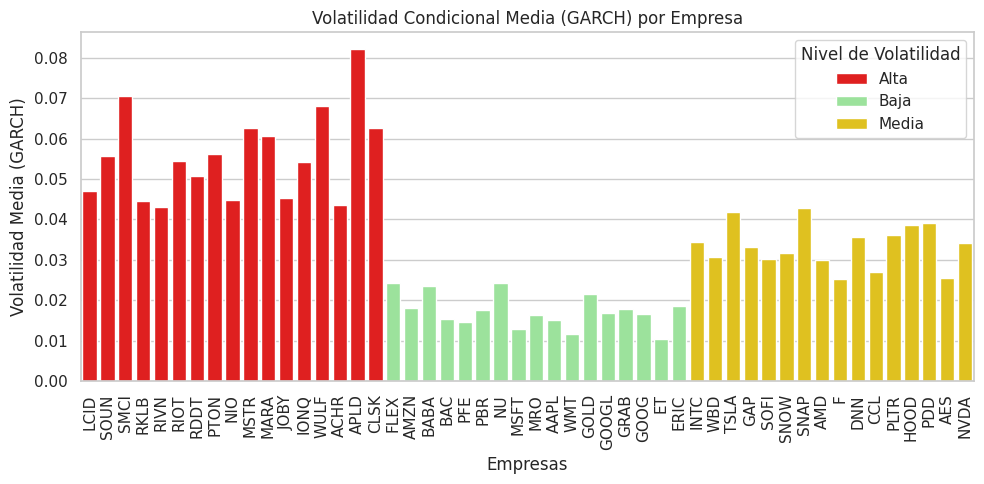

In [209]:
warnings.filterwarnings("ignore", category=UserWarning)                         # IGNORA LOS MENSAJES DE ADVERTENCIA
volatilidad_garch = pd.DataFrame(index=returns.index)                           # CREA UN DATAFRAME VACÍO PARA GUARDAR LA VOLATILIDAD DE LAS ACCIONES

for ticker in returns.columns:                                                 # RECORRE CADA ACCIÓN EN EL DATAFRAME DE RETORNOS
    try:
        returns_scaled = returns[ticker] * 100                                  # ESCALA LOS RETORNOS PARA MEJORAR EL FUNCIONAMIENTO DEL MODELO
        with contextlib.redirect_stdout(open(os.devnull, 'w')):                 # OCULTA MENSAJES INNECESARIOS DEL MODELO
            modelo_garch = arch_model(returns_scaled, vol='GARCH', p=1, q=1)    # CREA UN MODELO GARCH PARA CALCULAR LA VOLATILIDAD
            resultados = modelo_garch.fit(disp="off")                           # AJUSTA EL MODELO A LOS DATOS
        volatilidad_garch[ticker] = resultados.conditional_volatility / 100     # GUARDA LA VOLATILIDAD CALCULADA, DES-ESCALADA
    except Exception as e:
        print(f"Error al ajustar GARCH para {ticker}: {e}")                     # MUESTRA UN MENSAJE SI HAY UN ERROR EN EL MODELO

volatilidad_garch_media = volatilidad_garch.mean()                              # CALCULA EL PROMEDIO DE LA VOLATILIDAD PARA CADA ACCIÓN

volatilidad_garch_categoria = pd.DataFrame({                                    # CREA UN NUEVO DATAFRAME PARA CLASIFICAR LAS ACCIONES
    'Empresa': volatilidad_garch.columns,                                       # ASIGNA LOS NOMBRES DE LAS ACCIONES
    'Volatilidad Media (GARCH)': volatilidad_garch_media                        # ASIGNA LA VOLATILIDAD PROMEDIO DE CADA ACCIÓN
})

bajo_garch = volatilidad_garch_media.quantile(0.33)                             # CALCULA EL PERCENTIL 33 PARA DEFINIR VOLATILIDAD BAJA
medio_garch = volatilidad_garch_media.quantile(0.66)                            # CALCULA EL PERCENTIL 66 PARA DEFINIR VOLATILIDAD MEDIA

volatilidad_garch_categoria['Nivel de Volatilidad'] = 'Alta'                    # ASIGNA POR DEFECTO "ALTA" A TODAS LAS ACCIONES
volatilidad_garch_categoria.loc[                                                # RECLASIFICA COMO "MEDIA" SEGÚN EL PERCENTIL
    volatilidad_garch_categoria['Volatilidad Media (GARCH)'] <= medio_garch,
    'Nivel de Volatilidad'
] = 'Media'
volatilidad_garch_categoria.loc[                                                # RECLASIFICA COMO "BAJA" SEGÚN EL PERCENTIL
    volatilidad_garch_categoria['Volatilidad Media (GARCH)'] <= bajo_garch,
    'Nivel de Volatilidad'
] = 'Baja'

volatilidad_garch_categoria = volatilidad_garch_categoria.sort_values(by='Nivel de Volatilidad')  # ORDENA LAS ACCIONES POR NIVEL DE VOLATILIDAD

colores = {'Baja': 'lightgreen', 'Media': 'gold', 'Alta': 'red'}                # DEFINE LOS COLORES PARA CADA NIVEL DE VOLATILIDAD

plt.figure(figsize=(10, 5))                                                     # CREA UNA FIGURA PARA EL GRÁFICO
sns.barplot(                                                                    # CREA UN GRÁFICO DE BARRAS PARA LAS ACCIONES
    x='Empresa',
    y='Volatilidad Media (GARCH)',
    hue='Nivel de Volatilidad',
    data=volatilidad_garch_categoria,
    palette=colores
)
plt.title('Volatilidad Condicional Media (GARCH) por Empresa')                  # TITULO DEL GRÁFICO
plt.xlabel('Empresas')                                                          # ETIQUETA DEL EJE X
plt.ylabel('Volatilidad Media (GARCH)')                                         # ETIQUETA DEL EJE Y
plt.xticks(rotation=90)                                                         # ROTA LAS ETIQUETAS DE LAS ACCIONES EN EL EJE X
plt.legend(title='Nivel de Volatilidad')                                        # AGREGA UNA LEYENDA PARA LOS NIVELES DE VOLATILIDAD
plt.tight_layout()                                                              # AJUSTA EL GRÁFICO PARA EVITAR QUE SE CORTEN ELEMENTOS
plt.show()                                                                      # MUESTRA EL GRÁFICO





A 1.8 RELACION ENTRE RETORNOS Y VOLATILIDAD

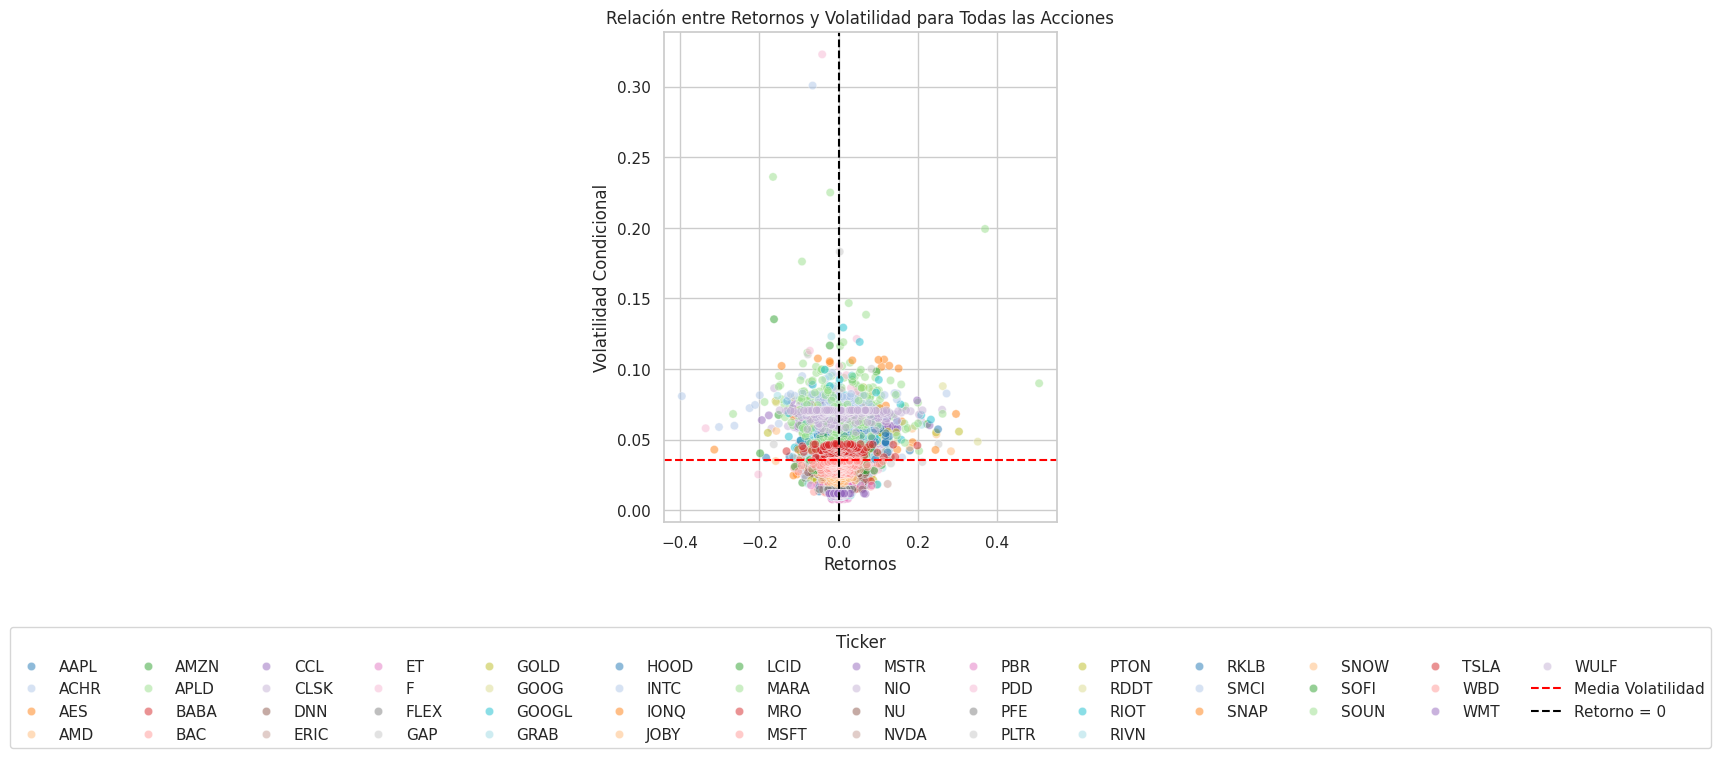

In [210]:

combined_data = pd.DataFrame()
for ticker in returns.columns:
    temp_data = pd.DataFrame({
        'Returns': returns[ticker],                                              # RETORNOS
        'Volatility': volatilidad_garch[ticker],                                 # VOLATILIDAD CONDICIONAL
        'Ticker': ticker                                                         # IDENTIFICADOR DE LA ACCIÓN
    })
    combined_data = pd.concat([combined_data, temp_data])                        # CONCATENAR AL DATAFRAME COMBINADO

plt.figure(figsize=(12, 8))                                                     # CREA UNA FIGURA DE TAMAÑO 12x8
sns.scatterplot(                                                                # CREA UN GRÁFICO DE DISPERSIÓN
    data=combined_data,                                                         # USA LOS DATOS COMBINADOS DE RETORNOS Y VOLATILIDAD
    x='Returns',                                                                # EJE X: RETORNOS
    y='Volatility',                                                             # EJE Y: VOLATILIDAD CONDICIONAL
    hue='Ticker',                                                               # DIFERENCIA LAS ACCIONES POR COLORES
    alpha=0.5,                                                                  # AJUSTA LA TRANSPARENCIA DE LOS PUNTOS
    palette='tab20'                                                             # USA UNA PALETA DE 20 COLORES
)
plt.axhline(combined_data['Volatility'].mean(), linestyle='--', color='red',    # AGREGA UNA LÍNEA HORIZONTAL PARA LA VOLATILIDAD PROMEDIO
            label='Media Volatilidad')
plt.axvline(0, linestyle='--', color='black', label='Retorno = 0')              # AGREGA UNA LÍNEA VERTICAL EN X=0 PARA LOS RETORNOS
plt.title('Relación entre Retornos y Volatilidad para Todas las Acciones')      # TITULO DEL GRÁFICO
plt.xlabel('Retornos')                                                          # ETIQUETA DEL EJE X
plt.ylabel('Volatilidad Condicional')                                           # ETIQUETA DEL EJE Y
plt.legend(                                                                     # CONFIGURA LA LEYENDA
    bbox_to_anchor=(0.5, -0.2),                                                 # MUEVE LA LEYENDA DEBAJO DEL GRÁFICO
    loc='upper center',                                                         # UBICA LA LEYENDA CENTRADA
    ncol=14,                                                                    # DISTRIBUYE LA LEYENDA EN 14 COLUMNAS
    title='Ticker'                                                              # AGREGA UN TÍTULO A LA LEYENDA
)
plt.grid(True)                                                                  # MUESTRA UNA CUADRÍCULA EN EL GRÁFICO
plt.tight_layout()                                                              # AJUSTA EL GRÁFICO PARA QUE TODO QUEPA BIEN
plt.show()                                                                      # MUESTRA EL GRÁFICO



B 1 - MATRIZ DE CORRELACION DE LOS RETORNOS DEL PORTAFOLIO

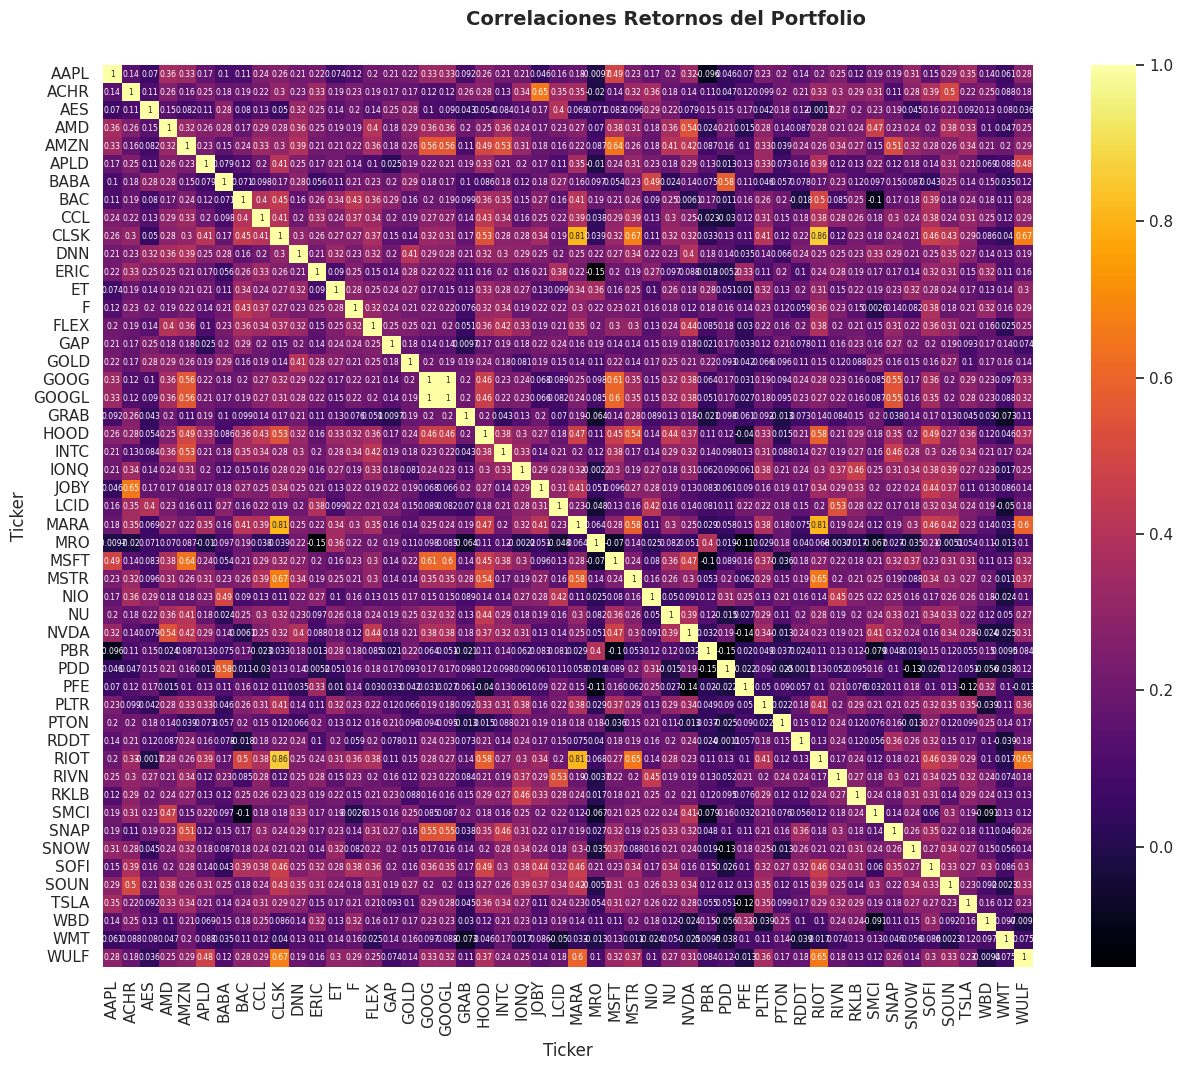

In [211]:
corr_matrix = returns.corr(method = "pearson")                                              # CALCULA LA MATRIZ DE CORRELACION CON EL METODO PEARSON
corr_matrix
fig, ax = plt.subplots(1, 1, figsize=(15, 11))                                              # TAMAÑAO DEL GRAFICO
corr = returns.corr()                                                                       # CALCULA LA CORRELACION DE LOS RETORNOS
sns.heatmap(corr, ax = ax, cmap = 'inferno', annot = True , annot_kws={"size": 5.5})        # MAPA DE CALOR, COLORES Y TAMAÑO DE INFORMACION
fig.subplots_adjust(top = 0.93)                                                             # AJUSTA EL GRAFICO PARA EVITAR SUPERPOSICIONES
fig.suptitle('Correlaciones Retornos del Portfolio', fontsize = 14, fontweight = 'bold')    # TITULO DEL GRAFICO Y SUS DIMENSIONES
plt.show()                                                                                  # MUESTRA EL GRAFICO

B 1.1 MATRIZ DE RETORNOS CON BAJA CORRELACION

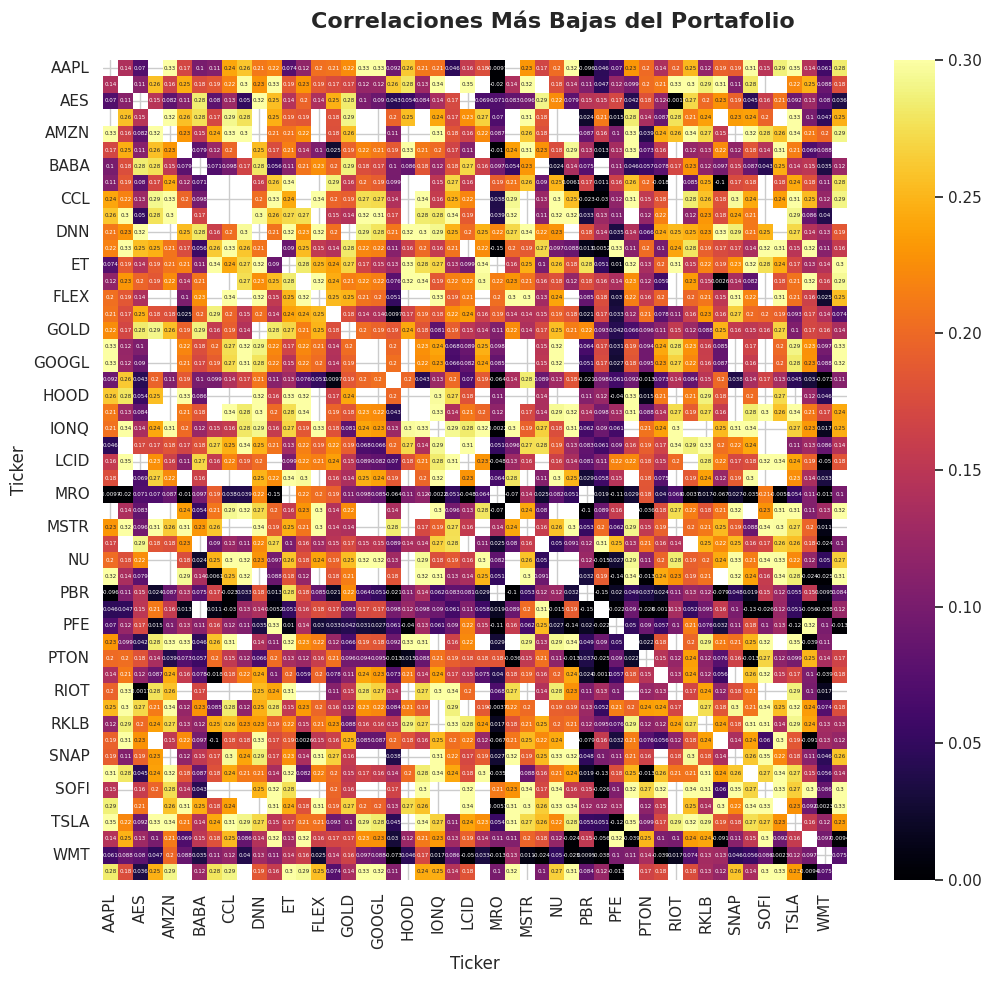

In [212]:
bajas = corr[corr < 0.35]                                                                              # FILTRA LOS VALORES MENORES A 0.35
bajas = bajas.dropna(how='all', axis=0).dropna(how='all', axis=1)                                      # LIMPIA EL GRAFICO DESPUES DE FILTRAR
if not bajas.empty:                                                                                    # VERIFICA VACIOS PARA EVITAR ERRORES EN EL GRAFICO
        fig, ax = plt.subplots(1, 1, figsize=(12, 10))                                                 # CREA UNA FIGURA Y SUS EJES
        sns.heatmap(bajas, ax=ax, cmap="inferno", annot=True, annot_kws={"size": 4}, vmin=0, vmax=0.3)
        fig.subplots_adjust(top=0.93)
        fig.suptitle('Correlaciones Más Bajas del Portafolio', fontsize=16, fontweight='bold')
        plt.show()

B 1.2 BLOXPOT DE LOS RETORNOS

<Axes: title={'center': 'Risk Box Plot'}>

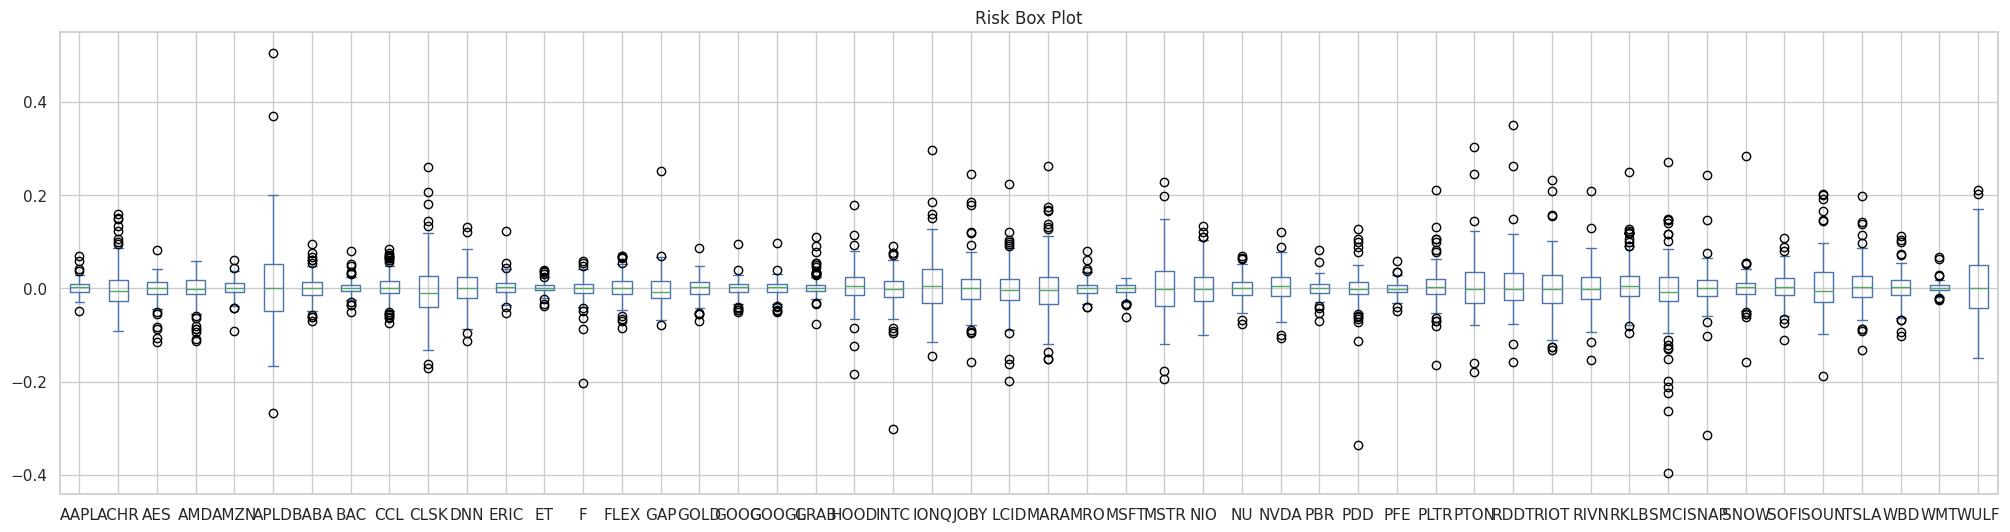

In [213]:
returns.plot(kind = "box", figsize = (25,6), title = "Risk Box Plot")

C- PCA Y CLUSTERING

C 1 PCA

In [214]:
from sklearn.preprocessing import StandardScaler                      # SIRVE PARA NORMALIZAR LOS DATOS, ESCALÁNDOLOS A UNA ESCALA COMÚN
scaler = StandardScaler()                                             # CREA UN OBJETO PARA ESCALAR LOS DATOS
scaled_retornos = scaler.fit_transform(returns)                       # NORMALIZA LOS RETORNOS PARA QUE TENGAN MEDIA 0 Y DESVIACIÓN ESTÁNDAR 1

# PCA CON 2 COMPONENTES PRINCIPALES
from sklearn.decomposition import PCA                                 # IMPORTA LA FUNCIÓN PARA REDUCIR DIMENSIONES (PCA)
pca = PCA(n_components=2)                                             # CREA UN OBJETO PCA PARA EXTRAER 2 COMPONENTES PRINCIPALES
pca_retornos = pca.fit_transform(scaled_retornos)                     # AJUSTA Y TRANSFORMA LOS DATOS ESCALADOS A 2 COMPONENTES PRINCIPALES
pca_df = pd.DataFrame(pca_retornos, columns=["PC1", "PC2"])           # CREA UN DATAFRAME CON LAS 2 COMPONENTES PRINCIPALES (PC1 Y PC2)


C 1.2 CLUSTERING KMEANS - DBSCAN - JERARQUICO - DENDOGRAMA

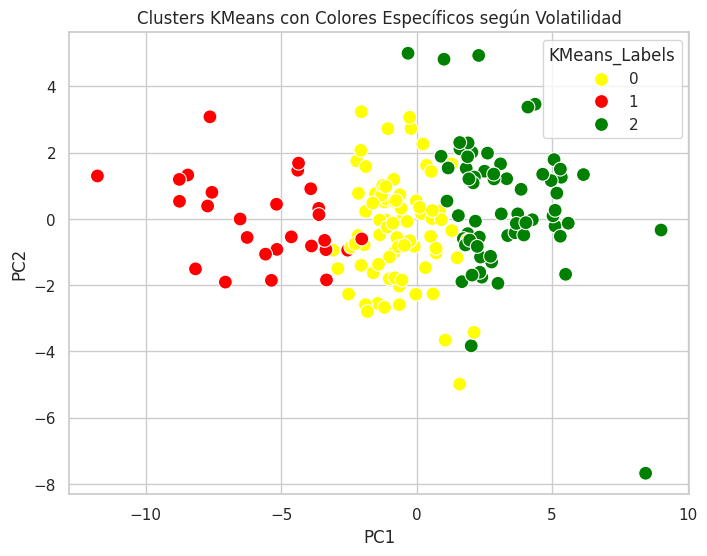

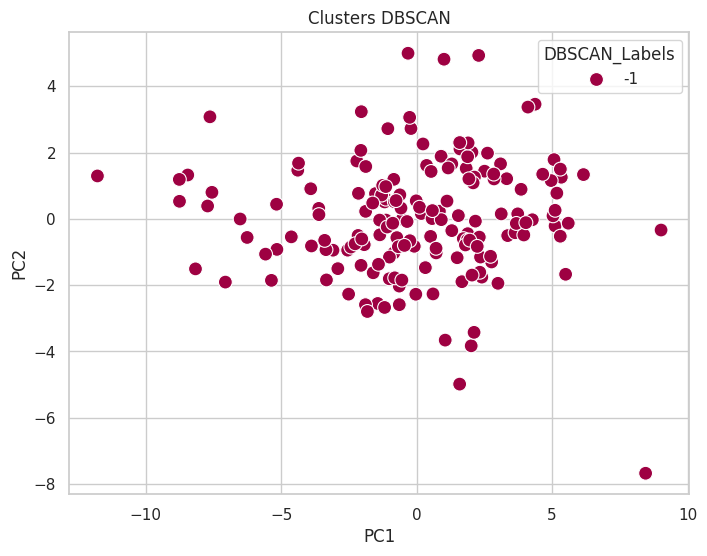

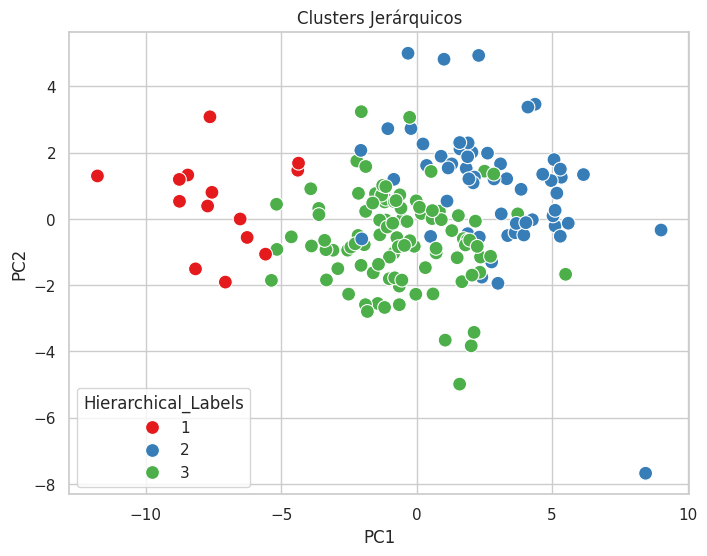

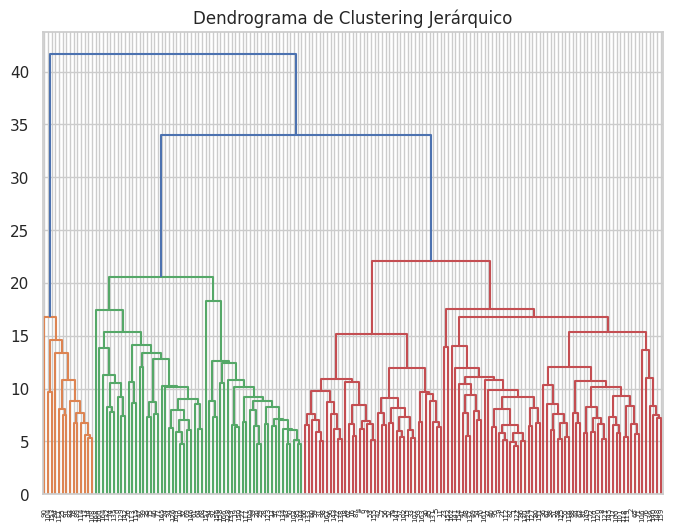

In [215]:
# CLUSTERING CON KMEANS
from sklearn.cluster import KMeans                                           # IMPORTA EL ALGORITMO KMEANS PARA AGRUPAR DATOS
kmeans = KMeans(n_clusters=3, random_state=42)                               # CREA UN MODELO KMEANS CON 3 GRUPOS Y UNA SEMILLA FIJA PARA RESULTADOS CONSISTENTES
kmeans_labels = kmeans.fit_predict(scaled_retornos)                          # AJUSTA EL MODELO A LOS DATOS ESCALADOS Y ASIGNA UNA ETIQUETA A CADA PUNTO
pca_df['KMeans_Labels'] = kmeans_labels                                      # AGREGA LAS ETIQUETAS DE KMEANS COMO UNA COLUMNA EN EL DATAFRAME

# CLUSTERING CON DBSCAN
from sklearn.cluster import DBSCAN                                           # IMPORTA EL ALGORITMO DBSCAN PARA AGRUPAR DATOS BASADOS EN DENSIDAD
dbscan = DBSCAN(eps=0.5, min_samples=5)                                      # CREA UN MODELO DBSCAN CON DISTANCIA EPSILON DE 0.5 Y MÍNIMO DE 5 PUNTOS POR CLUSTER
dbscan_labels = dbscan.fit_predict(scaled_retornos)                          # AJUSTA EL MODELO A LOS DATOS ESCALADOS Y ASIGNA UNA ETIQUETA A CADA PUNTO
pca_df['DBSCAN_Labels'] = dbscan_labels                                      # AGREGA LAS ETIQUETAS DE DBSCAN COMO UNA COLUMNA EN EL DATAFRAME

# CLUSTERING JERÁRQUICO
import scipy.cluster.hierarchy as shc                                        # IMPORTA HERRAMIENTAS PARA CLUSTERING JERÁRQUICO
hierarchy = shc.linkage(scaled_retornos, method='ward')                      # REALIZA EL CLUSTERING JERÁRQUICO USANDO EL MÉTODO WARD
hierarchical_labels = shc.fcluster(hierarchy, t=3, criterion='maxclust')     # ASIGNA PUNTOS A 3 GRUPOS BASADO EN EL CLUSTERING JERÁRQUICO
pca_df['Hierarchical_Labels'] = hierarchical_labels                         # AGREGA LAS ETIQUETAS DE CLUSTERING JERÁRQUICO COMO UNA COLUMNA EN EL DATAFRAME

# KMEANS
colores_kmeans = {0: 'yellow', 1: 'red', 2: 'green'}
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="KMeans_Labels",
                palette=colores_kmeans, s=100)
plt.title("Clusters KMeans con Colores Específicos según Volatilidad")
plt.show()

# DBSCAN
plt.figure(figsize=(8, 6))                                                   # CREA UNA FIGURA DE TAMAÑO 8x6 PARA EL GRÁFICO
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="DBSCAN_Labels",          # CREA UN GRÁFICO DE DISPERSIÓN PARA DBSCAN
                palette="Spectral", s=100)                                   # USA UNA PALETA DE COLORES "SPECTRAL" Y AJUSTA EL TAMAÑO DE LOS PUNTOS
plt.title('Clusters DBSCAN')                                                 # AÑADE UN TÍTULO AL GRÁFICO
plt.show()                                                                   # MUESTRA EL GRÁFICO EN PANTALLA

# JERÁRQUICO
plt.figure(figsize=(8, 6))                                                   # CREA UNA FIGURA DE TAMAÑO 8x6 PARA EL GRÁFICO
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Hierarchical_Labels",    # CREA UN GRÁFICO DE DISPERSIÓN PARA CLUSTERING JERÁRQUICO
                palette="Set1", s=100)                                       # USA UNA PALETA DE COLORES "SET1" Y AJUSTA EL TAMAÑO DE LOS PUNTOS
plt.title('Clusters Jerárquicos')                                            # AÑADE UN TÍTULO AL GRÁFICO
plt.show()                                                                   # MUESTRA EL GRÁFICO EN PANTALLA

# DENDROGRAMA
plt.figure(figsize=(8, 6))                                                   # CREA UNA FIGURA DE TAMAÑO 8x6 PARA EL GRÁFICO
shc.dendrogram(hierarchy)                                                    # DIBUJA EL DENDROGRAMA BASADO EN EL CLUSTERING JERÁRQUICO
plt.title('Dendrograma de Clustering Jerárquico')                            # AÑADE UN TÍTULO AL DENDROGRAMA
plt.show()                                                                   # MUESTRA EL DENDROGRAMA EN PANTALLA



B 1 VOLATILIDAD ESTOCASTICA Y VAR UNIVARIADO

B 1.1 VAR NO PARAMETRICO CON 3 ACTIVOS

VaR Histórico al 99% para TSLA: -947,779.33 USD
VaR Histórico al 99% para GAP: -901,138.57 USD
VaR Histórico al 99% para AMZN: -576,929.85 USD


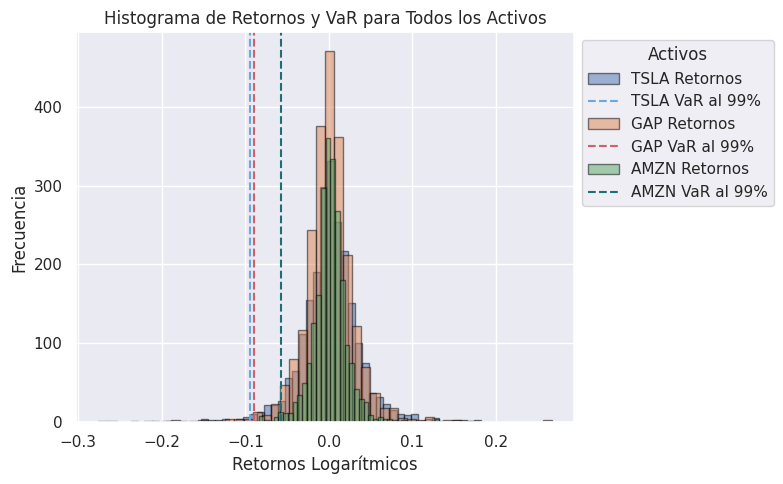

In [216]:
# CONFIGURACIONES
warnings.simplefilter("ignore")                                                 # IGNORA ADVERTENCIAS
sns.set_style('dark')                                                            # ESTILO OSCURO PARA LOS GRÁFICOS

# DEFINIR ACTIVOS Y POSICIÓN
tickers = ['TSLA', 'GAP', 'AMZN']                                                # LISTA DE TRES ACTIVOS A ANALIZAR CON NIVEL DE VOLATILIDAD ALTA-MEDIA Y BAJA
start_date = '2015-01-01'                                                        # FECHA INICIAL DE LOS DATOS A DESCARGAR
end_date = '2023-12-31'                                                          # FECHA DE FIN DE LOS DATOS
position = 10_000_000                                                            # POSICIÓN TOTAL EN DÓLARES PARA EL CÁLCULO DEL VaR
confidence_level = 0.99                                                          # NIVEL DE CONFIANZA DEL 99% PARA EL VaR

# DESCARGAR DATOS HISTÓRICOS
data = yf.download(tickers, start=start_date, end=end_date, progress=False)      # DESCARGA LOS DATOS HISTÓRICOS DE LOS ACTIVOS

# CALCULAR RETORNOS LOGARÍTMICOS
returns = np.log(data['Close'] / data['Close'].shift(1))                         # CALCULA LOS RETORNOS LOGARÍTMICOS DE LOS PRECIOS DE CIERRE
returns.dropna(inplace=True)                                                     # ELIMINA LOS VALORES NULOS RESULTANTES DEL CÁLCULO

# CALCULAR VAR HISTÓRICO PARA CADA ACTIVO
var_historical = {}                                                              # DICCIONARIO PARA GUARDAR LOS RESULTADOS DEL VaR
for ticker in tickers:                                                           # BUCLE PARA ITERAR SOBRE CADA ACTIVO
    var_percentile = np.percentile(returns[ticker], (1 - confidence_level) * 100)# CALCULA EL PERCENTIL CORRESPONDIENTE AL NIVEL DE CONFIANZA
    var_dollars = var_percentile * position                                      # CONVIERTE EL VaR A UNA CANTIDAD EN DÓLARES
    var_historical[ticker] = var_dollars                                         # GUARDA EL RESULTADO EN EL DICCIONARIO
    print(f"VaR Histórico al {confidence_level*100:.0f}% para {ticker}: {var_dollars:,.2f} USD")  # MUESTRA EL RESULTADO DEL VaR PARA CADA ACTIVO

# HISTOGRAMA COMPARATIVO PARA TODOS LOS ACTIVOS Y SUS VaR
plt.figure(figsize=(8, 5))                                                                        # CREA UNA FIGURA PARA EL GRÁFICO

for ticker in tickers:                                                                            # BUCLE PARA ITERAR SOBRE CADA ACTIVO
    plt.hist(returns[ticker], bins=50, alpha=0.5, label=f'{ticker} Retornos', edgecolor='black')  # AGREGA EL HISTOGRAMA DE RETORNOS
    var_value = np.percentile(returns[ticker], (1 - confidence_level) * 100)                      # CALCULA EL VALOR DEL VaR
    plt.axvline(var_value, linestyle='--', label=f'{ticker} VaR al {confidence_level*100:.0f}%', color=np.random.rand(3,))  # DIBUJA UNA LÍNEA PARA EL VaR

# CONFIGURACIONES DEL GRÁFICO
plt.title('Histograma de Retornos y VaR para Todos los Activos')                 # TÍTULO DEL GRÁFICO
plt.xlabel('Retornos Logarítmicos')                                              # ETIQUETA DEL EJE X
plt.ylabel('Frecuencia')                                                         # ETIQUETA DEL EJE Y
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), title='Activos')             # AGREGA LA LEYENDA AL GRÁFICO
plt.grid(True)                                                                   # MUESTRA UNA GRILLA EN EL GRÁFICO
plt.tight_layout()                                                               # AJUSTA LOS MÁRGENES DEL GRÁFICO PARA QUE NO SE SOBREPONGAN LOS ELEMENTOS
plt.show()                                                                       # MUESTRA EL GRÁFICO


B 1.2 VAR PARA 3 ACTIVOS UTILIZANDO ARCH(1), GARCH(1,1) y GJR-GARCH(1,1).AJUSTE (AIC,BIC)

[*********************100%***********************]  3 of 3 completed


Ajustando modelos para GAP...
Ajustando modelos para TSLA...
Ajustando modelos para AMZN...

Tabla de Criterios de Ajuste (AIC, BIC):
                              AIC           BIC
GAP  ARCH(1)         -9206.314384  -9189.141044
     GARCH(1,1)      -9418.774727  -9395.876941
     GJR-GARCH(1,1)  -9432.828838  -9404.206605
TSLA ARCH(1)         -8742.936082  -8725.762743
     GARCH(1,1)      -9034.539587  -9011.641801
     GJR-GARCH(1,1)  -9032.197593  -9003.575360
AMZN ARCH(1)        -11266.403018 -11249.229678
     GARCH(1,1)     -11476.181727 -11453.283940
     GJR-GARCH(1,1) -11496.852396 -11468.230163

Tabla de VaR:
        VaR ARCH(1)  VaR GARCH(1,1)  VaR GJR-GARCH(1,1)
GAP   276515.735746   197958.331122       166730.637101
TSLA  332727.361272   225479.720522       219311.970087
AMZN  174589.951321   126500.567980       125959.520719


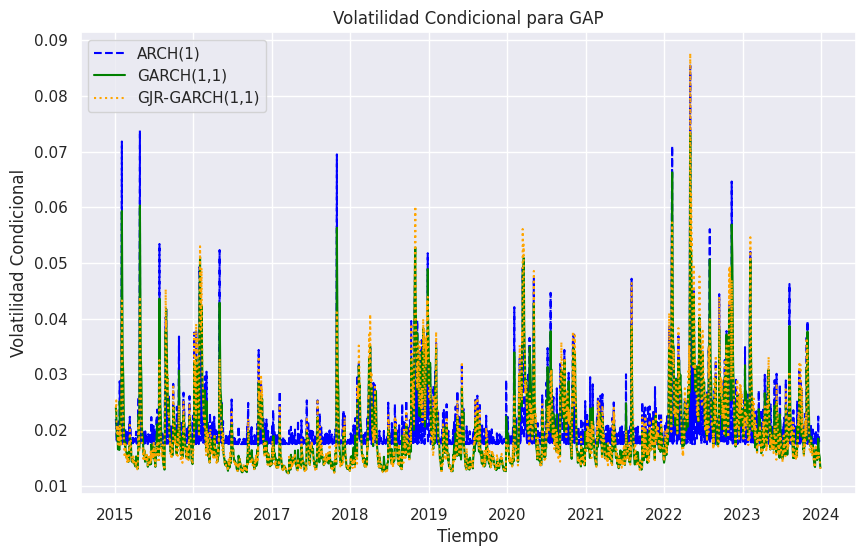

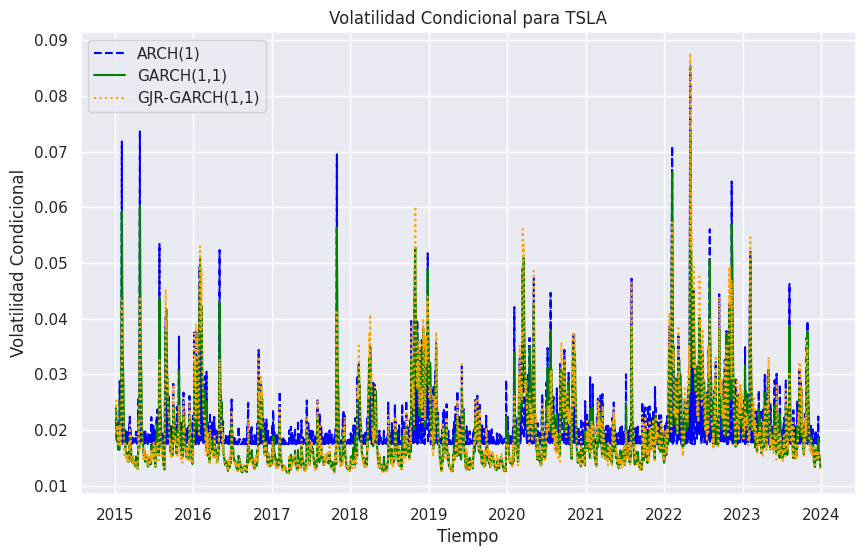

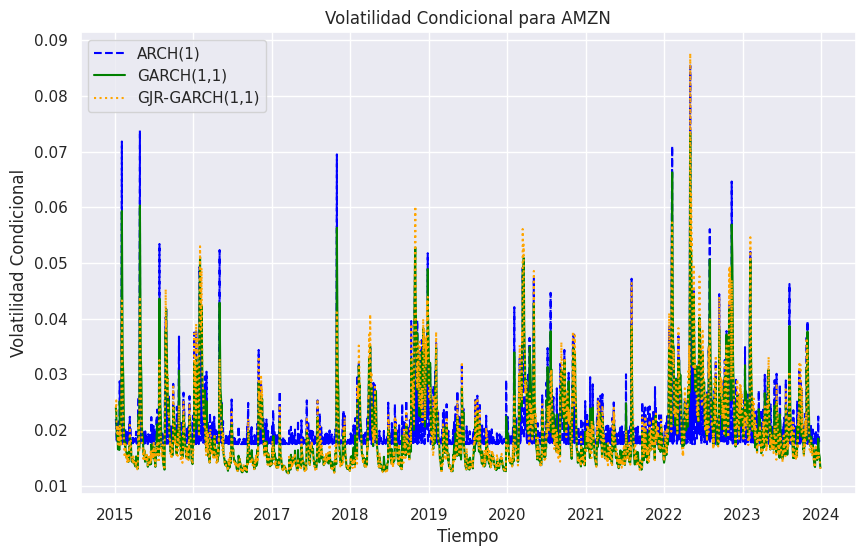

In [217]:

# CONFIGURAR ACTIVOS Y PARÁMETROS INICIALES
tickers = ['GAP', 'TSLA', 'AMZN']                                                # LISTA DE TRES ACTIVOS CON DISTINTOS NIVELES DE VOLATILIDAD
start_date = '2015-01-01'                                                        # FECHA INICIAL DE LOS DATOS A DESCARGAR
end_date = '2023-12-31'                                                          # FECHA FINAL DE LOS DATOS A DESCARGAR
position = 10_000_000                                                            # POSICIÓN TOTAL EN DÓLARES PARA EL CÁLCULO DEL VaR
confidence_level = 0.99                                                          # NIVEL DE CONFIANZA DEL 99%

# DESCARGAR DATOS HISTÓRICOS
data = yf.download(tickers, start=start_date, end=end_date)['Close']             # DESCARGAR PRECIOS DE CIERRE
returns = np.log(data / data.shift(1)).dropna()                                  # CALCULAR RETORNOS LOGARÍTMICOS DE LOS PRECIOS

# DICCIONARIOS PARA GUARDAR RESULTADOS
results_summary = {}                                                             # ALMACENARÁ LOS RESULTADOS DE AIC Y BIC DE CADA MODELO
var_results = {}                                                                 # ALMACENARÁ LOS RESULTADOS DEL VaR PARA CADA MODELO Y ACTIVO

# AJUSTAR MODELOS ARCH, GARCH Y GJR-GARCH Y CALCULAR VaR
for ticker in tickers:                                                           #BUCLE PARA ITERAR SOBRE CADA ACTIVO EN LA LISTA
    print(f"Ajustando modelos para {ticker}...")                                 # IMPRIMIR MENSAJE DE PROGRESO

    # ARCH(1)
    model_arch = arch_model(returns[ticker], vol='ARCH', p=1)                    # DEFINIR MODELO ARCH(1)
    result_arch = model_arch.fit(disp="off")                                     # AJUSTAR EL MODELO ARCH
    volatility_arch = result_arch.conditional_volatility                         # OBTENER LA VOLATILIDAD CONDICIONAL DEL MODELO ARCH
    var_arch = np.percentile(volatility_arch, (1 - confidence_level) * 100) * position  # CALCULAR EL VaR PARA ARCH

    # GARCH(1,1)
    model_garch = arch_model(returns[ticker], vol='GARCH', p=1, q=1)             # DEFINIR MODELO GARCH(1,1)
    result_garch = model_garch.fit(disp="off")                                   # AJUSTAR EL MODELO GARCH
    volatility_garch = result_garch.conditional_volatility                       # OBTENER LA VOLATILIDAD CONDICIONAL DEL MODELO GARCH
    var_garch = np.percentile(volatility_garch, (1 - confidence_level) * 100) * position  # CALCULAR EL VaR PARA GARCH

    # GJR-GARCH(1,1)
    model_gjr = arch_model(returns[ticker], vol='GARCH', p=1, q=1, o=1)          # DEFINIR MODELO GJR-GARCH(1,1)
    result_gjr = model_gjr.fit(disp="off")                                       # AJUSTAR EL MODELO GJR-GARCH
    volatility_gjr = result_gjr.conditional_volatility                           # OBTENER LA VOLATILIDAD CONDICIONAL DEL MODELO GJR-GARCH
    var_gjr = np.percentile(volatility_gjr, (1 - confidence_level) * 100) * position  # CALCULAR EL VaR PARA GJR-GARCH

    # GUARDAR RESULTADOS EN LOS DICCIONARIOS
    results_summary[ticker] = {                                                  # GUARDAR AIC Y BIC DE CADA MODELO PARA ESTE ACTIVO
        "ARCH(1)": {"AIC": result_arch.aic, "BIC": result_arch.bic},             # RESULTADOS PARA ARCH
        "GARCH(1,1)": {"AIC": result_garch.aic, "BIC": result_garch.bic},        # RESULTADOS PARA GARCH
        "GJR-GARCH(1,1)": {"AIC": result_gjr.aic, "BIC": result_gjr.bic},        # RESULTADOS PARA GJR-GARCH
    }
    var_results[ticker] = {                                                      # GUARDAR VaR PARA CADA MODELO DE ESTE ACTIVO
        "VaR ARCH(1)": var_arch,                                                 # VaR PARA ARCH
        "VaR GARCH(1,1)": var_garch,                                             # VaR PARA GARCH
        "VaR GJR-GARCH(1,1)": var_gjr,                                           # VaR PARA GJR-GARCH
    }

# CREAR TABLAS DE RESULTADOS
comparison_table = pd.DataFrame.from_dict(                                       # CREAR DATAFRAME PARA COMPARAR AIC Y BIC
    {(ticker, model): results_summary[ticker][model]
     for ticker in tickers for model in results_summary[ticker]},
    orient="index"                                                               # ORDENAR POR ÍNDICES
)

var_table = pd.DataFrame(var_results).T                                          # CREAR DATAFRAME PARA COMPARAR LOS VALORES DE VaR

# MOSTRAR TABLAS
print("\nTabla de Criterios de Ajuste (AIC, BIC):")                              # IMPRIMIR RESULTADOS DE AIC Y BIC
print(comparison_table)                                                          # MOSTRAR TABLA DE CRITERIOS DE AJUSTE
print("\nTabla de VaR:")                                                         # IMPRIMIR RESULTADOS DE VaR
print(var_table)                                                                 # MOSTRAR TABLA DE VaR

# GRAFICAR LA VOLATILIDAD CONDICIONAL PARA CADA ACTIVO
for ticker in tickers:                                                           # ITERAR SOBRE CADA ACTIVO
    plt.figure(figsize=(10, 6))                                                  # CONFIGURAR TAMAÑO DEL GRÁFICO
    plt.plot(volatility_arch, label="ARCH(1)", linestyle='--', color='blue')     # GRAFICAR VOLATILIDAD ARCH
    plt.plot(volatility_garch, label="GARCH(1,1)", linestyle='-', color='green')  # GRAFICAR VOLATILIDAD GARCH
    plt.plot(volatility_gjr, label="GJR-GARCH(1,1)", linestyle=':', color='orange')  # GRAFICAR VOLATILIDAD GJR-GARCH
    plt.title(f"Volatilidad Condicional para {ticker}")                          # TÍTULO DEL GRÁFICO
    plt.xlabel("Tiempo")                                                         # ETIQUETA PARA EL EJE X
    plt.ylabel("Volatilidad Condicional")                                        # ETIQUETA PARA EL EJE Y
    plt.legend()                                                                 # MOSTRAR LEYENDA
    plt.grid()                                                                   # AGREGAR CUADRÍCULA
    plt.show()                                                                   # MOSTRAR GRÁFICO





C ANALISIS DE DIAGNOSTICO DE LOS MODELOS

C 1.1 ANALISIS DE REZAGOS

Análisis ACF y PACF para GAP...


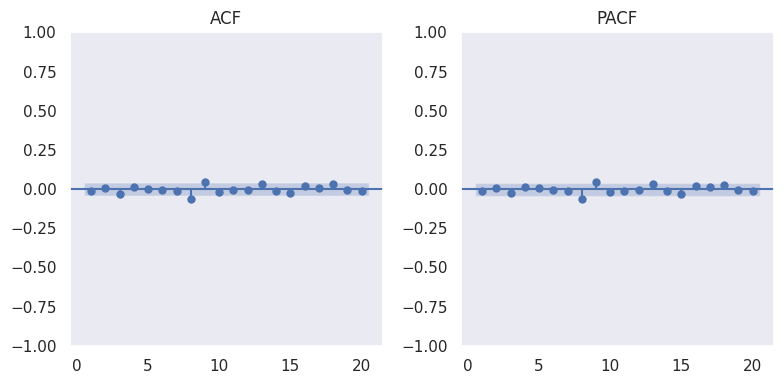

Análisis ACF y PACF para TSLA...


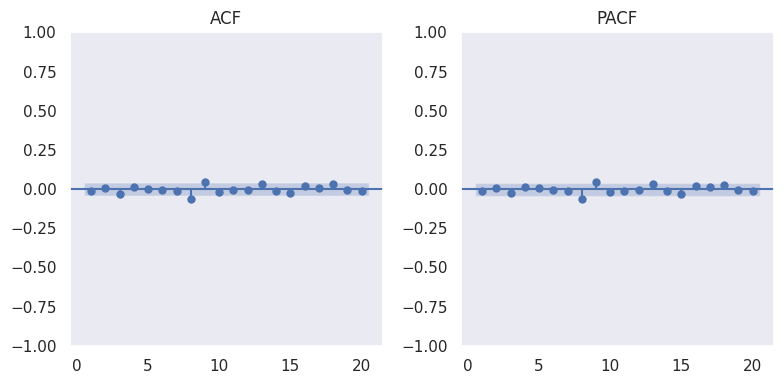

Análisis ACF y PACF para AMZN...


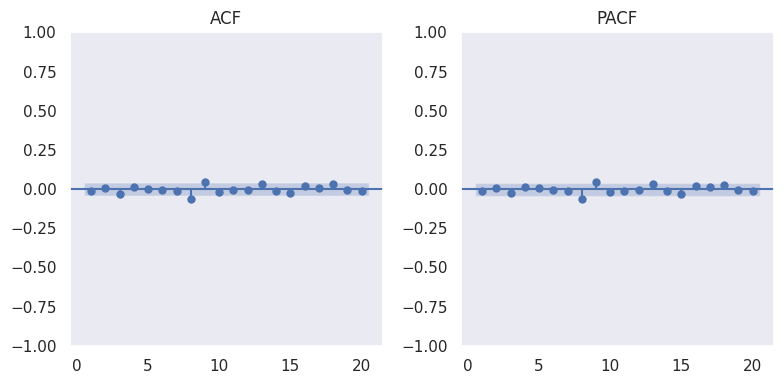

In [218]:

def plot_acf_pacf(serie, lags=None):                                  # DEFINE UNA FUNCIÓN PARA GRAFICAR ACF Y PACF
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))                   # CREA UN GRÁFICO CON 2 COLUMNAS
    plot_acf(serie, lags=lags, ax=axes[0], title='ACF', zero=False)   # GRAFICA LA ACF
    plot_pacf(serie, lags=lags, ax=axes[1], title='PACF', zero=False) # GRAFICA LA PACF
    plt.tight_layout()                                                # AJUSTA LOS ESPACIOS ENTRE GRÁFICOS
    plt.show()                                                        # MUESTRA LOS GRÁFICOS

for ticker in tickers:
    print(f"Análisis ACF y PACF para {ticker}...")
    residuals = result_garch.resid                                    # AJUSTA AL MODELO QUE ESTÉS ANALIZANDO (ARCH, GARCH O GJR-GARCH)
    plot_acf_pacf(residuals, lags=20)                                 # GRAFICA ACF Y PACF PARA LOS RESIDUOS


C 1.2 ANALISIS DE RESIDUOS

Análisis de residuos para GAP...


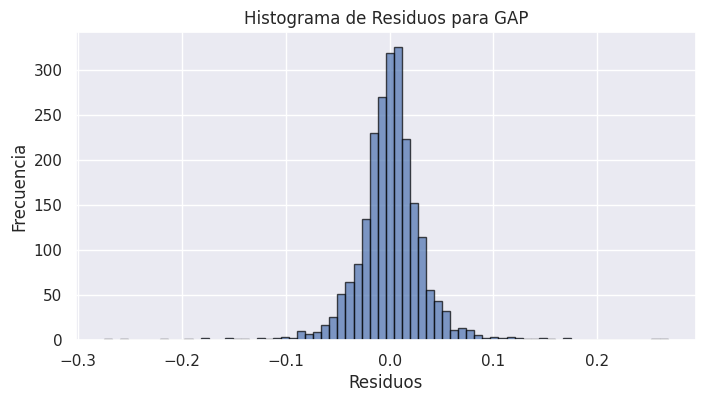

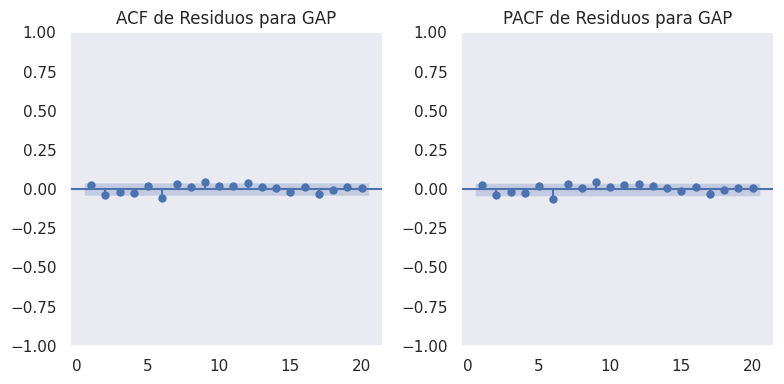

Prueba de Jarque-Bera para GAP:
Estadístico: 12105.33, p-valor: 0.0000
Los residuos de GAP no son normales (p < 0.05).
Análisis de residuos para TSLA...


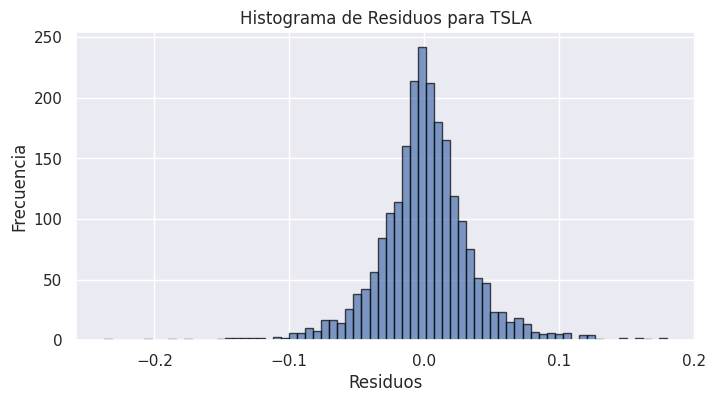

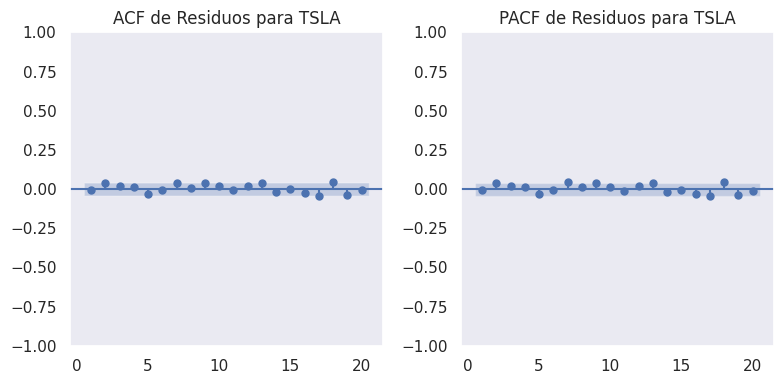

Prueba de Jarque-Bera para TSLA:
Estadístico: 1923.37, p-valor: 0.0000
Los residuos de TSLA no son normales (p < 0.05).
Análisis de residuos para AMZN...


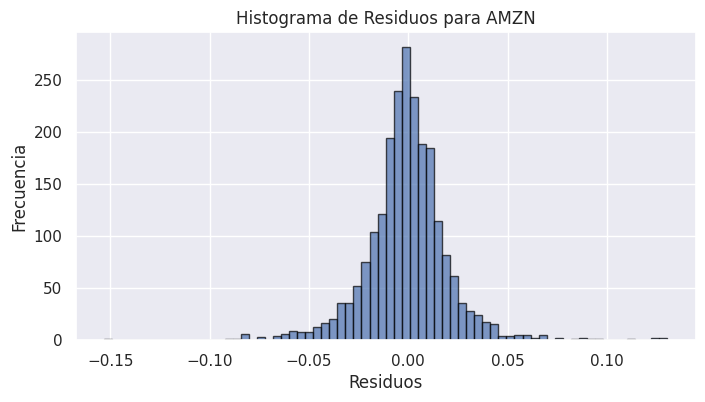

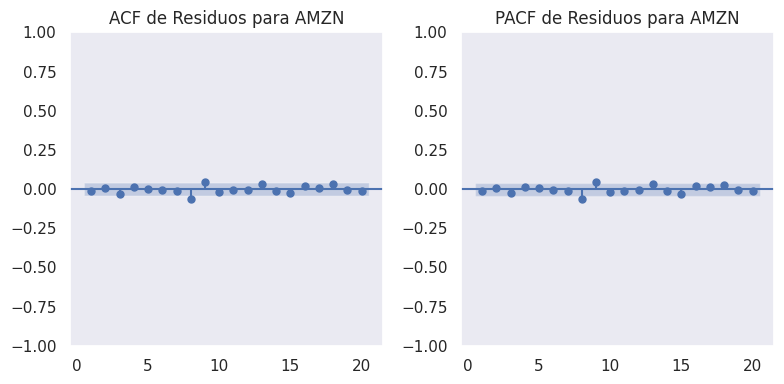

Prueba de Jarque-Bera para AMZN:
Estadístico: 3228.73, p-valor: 0.0000
Los residuos de AMZN no son normales (p < 0.05).


In [219]:

tickers = ['GAP', 'TSLA', 'AMZN']                                                # DEFINE LAS ACCIONES A ANALIZAR

for ticker in tickers:                                                           # ITERA SOBRE CADA ACCIÓN EN LA LISTA
    print(f"Análisis de residuos para {ticker}...")                              # IMPRIME EL NOMBRE DE LA ACCIÓN QUE SE ANALIZA

    # AJUSTAR EL MODELO GARCH(1,1)
    model_garch = arch_model(returns[ticker], vol='GARCH', p=1, q=1)             # DEFINE EL MODELO GARCH(1,1) PARA LA ACCIÓN
    result_garch = model_garch.fit(disp="off")                                   # AJUSTA EL MODELO GARCH SIN MOSTRAR DETALLES EN CONSOLA

    # OBTENER RESIDUOS DEL MODELO
    residuos = result_garch.resid                                                # GUARDA LOS RESIDUOS DEL MODELO AJUSTADO

    # GRAFICAR HISTOGRAMA DE LOS RESIDUOS
    plt.figure(figsize=(8, 4))                                                  # CREA UNA FIGURA PARA EL HISTOGRAMA
    plt.hist(residuos, bins=70, edgecolor='black', alpha=0.7)                    # GRAFICA EL HISTOGRAMA DE LOS RESIDUOS
    plt.title(f'Histograma de Residuos para {ticker}')                           # AGREGA EL TÍTULO AL GRÁFICO
    plt.xlabel('Residuos')                                                       # ETIQUETA DEL EJE X
    plt.ylabel('Frecuencia')                                                     # ETIQUETA DEL EJE Y
    plt.grid()                                                                   # MUESTRA UNA CUADRÍCULA
    plt.show()                                                                   # MUESTRA EL GRÁFICO

    # GRAFICAR ACF Y PACF DE LOS RESIDUOS
    plt.figure(figsize=(8, 4))                                                  # CREA UNA FIGURA PARA ACF Y PACF
    plt.subplot(1, 2, 1)                                                         # CREA EL PRIMER SUBGRÁFICO (ACF)
    plot_acf(residuos, lags=20, zero=False, ax=plt.gca())                        # GRAFICA LA ACF DE LOS RESIDUOS
    plt.title(f'ACF de Residuos para {ticker}')                                  # AGREGA EL TÍTULO AL GRÁFICO ACF
    plt.subplot(1, 2, 2)                                                         # CREA EL SEGUNDO SUBGRÁFICO (PACF)
    plot_pacf(residuos, lags=20, zero=False, ax=plt.gca())                       # GRAFICA LA PACF DE LOS RESIDUOS
    plt.title(f'PACF de Residuos para {ticker}')                                 # AGREGA EL TÍTULO AL GRÁFICO PACF
    plt.tight_layout()                                                           # AJUSTA LOS ESPACIOS ENTRE LOS GRÁFICOS
    plt.show()                                                                   # MUESTRA LOS GRÁFICOS ACF Y PACF

    # PRUEBA DE NORMALIDAD DE JARQUE-BERA
    from scipy.stats import jarque_bera                                          # IMPORTA LA PRUEBA JARQUE-BERA PARA EVALUAR NORMALIDAD
    jb_test = jarque_bera(residuos)                                              # APLICA LA PRUEBA DE JARQUE-BERA A LOS RESIDUOS
    print(f"Prueba de Jarque-Bera para {ticker}:")                               # IMPRIME EL TÍTULO DE LOS RESULTADOS
    print(f"Estadístico: {jb_test[0]:.2f}, p-valor: {jb_test[1]:.4f}")           # IMPRIME EL ESTADÍSTICO Y EL P-VALOR DE LA PRUEBA
    if jb_test[1] < 0.05:  # SI EL P-VALOR ES MENOR A 0.05
        print(f"Los residuos de {ticker} no son normales (p < 0.05).")           # INDICA QUE LOS RESIDUOS NO SON NORMALES
    else:  # SI EL P-VALOR ES MAYOR O IGUAL A 0.05
        print(f"Los residuos de {ticker} son normales (p >= 0.05).")             # INDICA QUE LOS RESIDUOS SON NORMALES





C 1.3 - ANALISIS DE LOS METODOS COMPARADOS


EL MODELO GJR-GARCH(1,1) HA DEMOSTRADO SER LA MEJOR OPCIÓN PARA GESTIONAR LOS RIESGOS FINANCIEROS EN LOS ACTIVOS ANALIZADOS. SU DESEMPEÑO SUPERIOR SE BASA EN SU CAPACIDAD PARA AJUSTARSE DE MANERA ÓPTIMA A LOS DATOS HISTÓRICOS Y PROPORCIONAR ESTIMACIONES CONFIABLES Y CONSERVADORAS DE LAS PÉRDIDAS POTENCIALES. ESTO LO HACE ESPECIALMENTE ÚTIL PARA TOMAR DECISIONES EN ESCENARIOS DE ALTA INCERTIDUMBRE.

ADEMÁS, EL CRITERIO BIC HA REFORZADO ESTA ELECCIÓN. COMO MÉTODO QUE PENALIZA LA COMPLEJIDAD DEL MODELO, EL BIC INDICÓ QUE EL MODELO GJR-GARCH(1,1) LOGRÓ UN BALANCE IDEAL ENTRE SIMPLICIDAD Y PRECISIÓN, VALIDANDO SU ADECUACIÓN PARA ESTE ANÁLISIS.

LOS RESULTADOS DE LA PRUEBA DE JARQUE-BERA TAMBIÉN REVELARON QUE LOS RESIDUOS DE LOS TRES ACTIVOS ANALIZADOS (GAP, TSLA, Y AMZN) NO SIGUEN UNA DISTRIBUCIÓN NORMAL (P < 0.05). ESTO ES CONSISTENTE CON LAS CARACTERÍSTICAS TÍPICAS DE LOS DATOS FINANCIEROS, QUE SUELEN PRESENTAR COLAS MÁS PESADAS Y ASIMETRÍAS. TALES ATRIBUTOS SON CAPTURADOS DE MANERA EFECTIVA POR EL GJR-GARCH(1,1), HACIÉNDOLO AÚN MÁS ADECUADO PARA ESTE CONTEXTO.

D- FORCAST A 5 DIAS GJR-GARCH (1,1)


Forecast de VaR a 5 días:
             Día 1         Día 2         Día 3         Día 4         Día 5
TSLA  25961.614302  26047.263042  26131.834277  26215.345860  26297.815220
AMZN   7877.879152   8243.311373   8577.997422   8886.064700   9170.800405
GAP   34550.058044  34555.018991  34559.966201  34564.899715  34569.819571


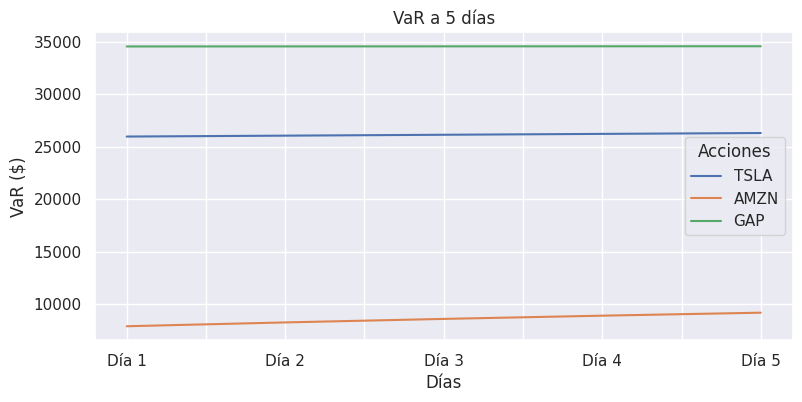

In [220]:
tickers = ['TSLA', 'AMZN', 'GAP']                                                                                 # LISTA DE ACCIONES A ANALIZAR
confidence_level = 0.99                                                                                           # NIVEL DE CONFIANZA DEL 99% PARA EL VaR
position = 10_000_000                                                                                             # TAMAÑO DE LA POSICIÓN EN DÓLARES
forecast_days = 5                                                                                                 # DÍAS DE PRONÓSTICO

forecast_results = {}                                                                                             # DICCIONARIO PARA GUARDAR LOS RESULTADOS DEL PRONÓSTICO

# FORECAST DE 5 DIAS
for ticker in tickers:                                                                                            # ITERA SOBRE CADA ACCIÓN
    result = arch_model(returns[ticker] * 100, vol='GARCH', p=1, q=1, o=1).fit(disp="off")                        # AJUSTA EL MODELO GJR-GARCH(1,1) A LOS DATOS ESCALADOS (MULTIPLICADOS POR 100)
    forecast_volatility = result.forecast(horizon=forecast_days).variance.values[-1] ** 0.5 / 100                 # GENERA LA VOLATILIDAD PRONOSTICADA PARA LOS PRÓXIMOS 5 DÍAS

# CALCULO DEL VAR
    var_values = -forecast_volatility * position * np.percentile(returns[ticker], (1 - confidence_level) * 100)   # CALCULA EL VaR CON LA VOL PRONOSTICADA Y NIVEL DE CONFIANZA
    forecast_results[ticker] = var_values                                                                         # GUARDA LOS RESULTADOS EN EL DICCIONARIO

# DATAFRAME
forecast_df = pd.DataFrame(forecast_results, index=[f'Día {i+1}' for i in range(forecast_days)]).T                # CREA LA TABLA DEL FORECAST CON DIAS Y SUS RESULTADOS
print("\nForecast de VaR a 5 días:")                                                                              # IMPRIME UN MENSAJE DESCRIPTIVO
print(forecast_df)                                                                                                # MUESTRA LA TABLA CON LOS RESULTADOS

# VISUALZIACION
forecast_df.T.plot(figsize=(9, 4), title='VaR a 5 días', xlabel='Días', ylabel='VaR ($)')                         # GRAFICO Y SUS EJES X E Y
plt.legend(title='Acciones')                                                                                      # AGREGA UNA LEYENDA AL GRÁFICO
plt.grid()                                                                                                        # AGREGA UNA CUADRÍCULA AL GRÁFICO
plt.show()                                                                                                        # MUESTRA EL GRÁFICO



E - COMPARACION DE MODELOS GJR-GARCH / MACHINE LEARNING SVMRegressor y RandomForestRegressor

In [237]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from arch import arch_model
import yfinance as yf

# DEFINIR LAS ACCIONES A ANALIZAR
acciones_prueba = ["NVDA", "SMCI", "SOUN", "MARA", "TSLA", "F", "NIO", "PLTR", "FLEX", "GRAB",
                  "MSTR", "SOFI", "CLSK", "ACHR", "PFE", "LCID", "NU", "SNAP", "GOOGL", "AAPL",
                  "BAC", "PBR", "INTC", "MRO", "RDDT", "GAP", "CCL", "AMZN", "RIOT", "RIVN",
                  "AES", "RKLB", "IONQ", "WBD", "WULF", "ERIC", "BABA", "MSFT", "GOOG", "WMT",
                  "JOBY", "DNN", "APLD", "ET", "GOLD", "AMD", "HOOD", "PDD", "PTON", "SNOW"]

# Cargar datos desde Yahoo Finance
data = yf.download(acciones_prueba, start='2019-01-01', end='2024-12-10')['Adj Close']
returns = data.pct_change().dropna()  # Calcular retornos diarios

# CREAR LOS REZAGOS COMO CARACTERÍSTICAS
lagged_returns = returns.copy()  # HACER UNA COPIA DE LOS DATOS DE RETORNOS

for lag in range(1, 6):  # CREAR 5 REZAGOS
    for ticker in acciones_prueba:  # ITERAR SOBRE LAS ACCIONES DE PRUEBA
        column_name = f'{ticker}_Lag_{lag}'  # CREAR EL NOMBRE DE LA COLUMNA
        lagged_returns[column_name] = returns[ticker].shift(lag)  # AGREGAR LOS REZAGOS A LOS DATOS
    lagged_returns.dropna(inplace=True)  # ELIMINAR VALORES NULOS POR LOS REZAGOS

# Verificar las columnas de lagged_returns
print(f"Columnas de lagged_returns: {lagged_returns.columns[:10]}")  # Verificar las primeras 10 columnas

# DIVIDIR LOS DATOS EN CARACTERÍSTICAS (X) Y VARIABLES OBJETIVO (Y)
X = lagged_returns[[col for col in lagged_returns.columns if 'Lag' in col]]  # X SON LOS REZAGOS
y = lagged_returns[acciones_prueba]  # Y SON LOS RETORNOS ACTUALES (UNA COLUMNA POR ACCIÓN)

# Verificar que las columnas en y estén correctamente asignadas
print(f"Columnas de y: {y.columns.tolist()}")  # Verifica las columnas de y

# DIVIDIR EN ENTRENAMIENTO Y PRUEBA (80%-20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  # DIVIDE LOS DATOS EN ENTRENAMIENTO Y PRUEBA

# Verificar las primeras filas de y_train y y_test
print(f"Primeras filas de y_train: {y_train.head()}")  # Verifica que las columnas estén alineadas

# ESCALAR LOS DATOS
scaler = StandardScaler()  # CREAR UN ESCALADOR ESTÁNDAR
X_train_scaled = scaler.fit_transform(X_train)  # AJUSTAR Y ESCALAR LOS DATOS DE ENTRENAMIENTO
X_test_scaled = scaler.transform(X_test)  # ESCALAR LOS DATOS DE PRUEBA

# ENTRENAR MODELOS PARA CADA ACCIÓN
results = {}  # DICCIONARIO PARA GUARDAR RESULTADOS

# ITERAR SOBRE CADA ACCIÓN DE PRUEBA
for ticker in acciones_prueba:
    print(f"\nANALIZANDO {ticker}...")  # IMPRIMIR EL PROGRESO

    # Verificar que 'NVDA' está en y_train antes de acceder a los datos
    if ticker not in y_train.columns:
        print(f"¡Error! El ticker {ticker} no está en y_train.")
        continue  # Si el ticker no está presente, se salta este ticker

    # ENTRENAR EL MODELO SVMREGRESSOR (SVM)
    svm_model = SVR(kernel='rbf')  # CREAR UN MODELO SVM CON KERNEL RADIAL
    svm_model.fit(X_train_scaled, y_train[ticker])  # ENTRENAR CON LOS DATOS DE LA ACCIÓN
    svm_predictions = svm_model.predict(X_test_scaled)  # HACER PREDICCIONES CON LOS DATOS DE PRUEBA
    svm_rmse = mean_squared_error(y_test[ticker], svm_predictions, squared=False)  # CALCULAR EL ERROR RMSE

    # ENTRENAR EL MODELO RANDOMFORESTREGRESSOR (RANDOM FOREST)
    rf_model = RandomForestRegressor(n_estimators=100, random_state=42)  # CREAR UN MODELO RANDOM FOREST
    rf_model.fit(X_train_scaled, y_train[ticker])  # ENTRENAR EL MODELO CON LOS DATOS DE LA ACCIÓN
    rf_predictions = rf_model.predict(X_test_scaled)  # HACER PREDICCIONES CON LOS DATOS DE PRUEBA
    rf_rmse = mean_squared_error(y_test[ticker], rf_predictions, squared=False)  # CALCULAR EL ERROR RMSE

    # ENTRENAR EL MODELO GJR-GARCH(1,1)
    model_gjr = arch_model(returns[ticker] * 100, vol='GARCH', p=1, q=1, o=1)  # CONFIGURAR EL MODELO GJR-GARCH
    result_gjr = model_gjr.fit(disp='off')  # AJUSTAR EL MODELO
    forecast_gjr = result_gjr.forecast(horizon=30)  # HACER UN FORECAST A 30 DÍAS
    gjr_predictions = forecast_gjr.variance.values[-1] ** 0.5 / 100  # CALCULAR LA VOLATILIDAD PREVISTA

    # GUARDAR RESULTADOS
    results[ticker] = {
        "SVM_RMSE": svm_rmse,
        "RF_RMSE": rf_rmse,
        "GJR_VOLATILITY": gjr_predictions[0]
    }

    # IMPRIMIR RESULTADOS PARA LA ACCIÓN
    print(f"- ERROR RMSE SVM: {svm_rmse:.2f}")
    print(f"- ERROR RMSE RANDOM FOREST: {rf_rmse:.2f}")
    print(f"- VOLATILIDAD PREVISTA GJR-GARCH: {gjr_predictions[0]:.4f}")

# Mostrar los resultados
results_df = pd.DataFrame(results).T  # CONVERTIR EL DICCIONARIO EN UN DATAFRAME
print("\nRESULTADOS COMPARADOS:")
print(results_df)







[*********************100%***********************]  50 of 50 completed


Columnas de lagged_returns: Index(['AAPL', 'ACHR', 'AES', 'AMD', 'AMZN', 'APLD', 'BABA', 'BAC', 'CCL',
       'CLSK'],
      dtype='object', name='Ticker')
Columnas de y: ['NVDA', 'SMCI', 'SOUN', 'MARA', 'TSLA', 'F', 'NIO', 'PLTR', 'FLEX', 'GRAB', 'MSTR', 'SOFI', 'CLSK', 'ACHR', 'PFE', 'LCID', 'NU', 'SNAP', 'GOOGL', 'AAPL', 'BAC', 'PBR', 'INTC', 'MRO', 'RDDT', 'GAP', 'CCL', 'AMZN', 'RIOT', 'RIVN', 'AES', 'RKLB', 'IONQ', 'WBD', 'WULF', 'ERIC', 'BABA', 'MSFT', 'GOOG', 'WMT', 'JOBY', 'DNN', 'APLD', 'ET', 'GOLD', 'AMD', 'HOOD', 'PDD', 'PTON', 'SNOW']
Primeras filas de y_train: Ticker          NVDA      SMCI      SOUN      MARA      TSLA         F  \
Date                                                                     
2024-09-19  0.039693  0.000733  0.032990  0.007171  0.073592 -0.005464   
2024-10-24  0.006091  0.019180  0.060241  0.008301  0.219190  0.016275   
2024-11-22 -0.032181  0.116162  0.181948  0.076510  0.038040  0.035185   
2024-05-24  0.025723  0.043074  0.014028  0.056275

E 1.1 VISUALIZACION DE COMPARACION

<Figure size 1200x600 with 0 Axes>

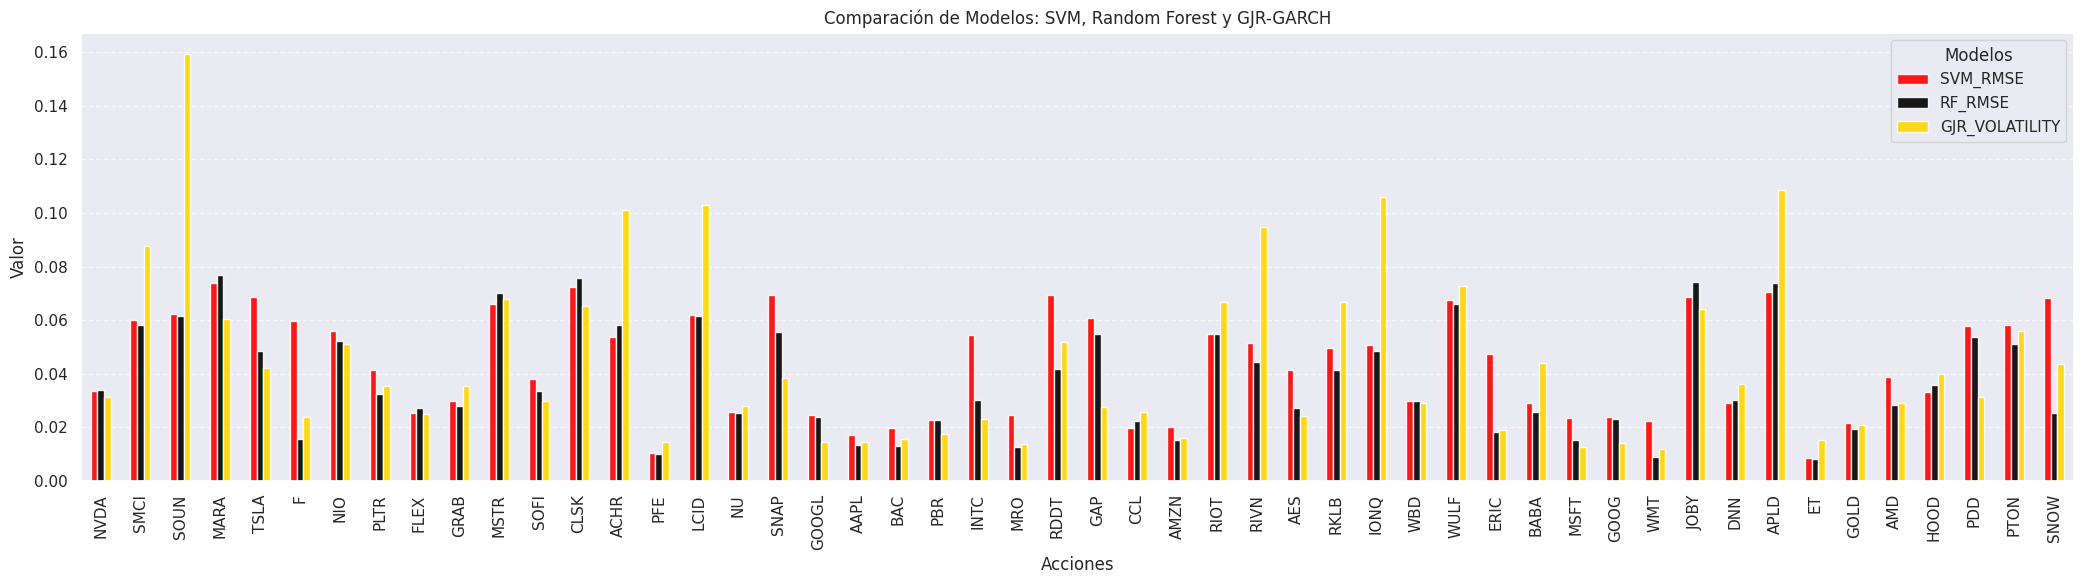

In [238]:
# GRAFICAR COMPARACIÓN DE TODOS LOS MODELOS EN UN SOLO GRÁFICO
plt.figure(figsize=(12, 6))                                       # DIMENSIONES DEL GRAFICO
results_df.plot(
    kind='bar',                                                   # GRÁFICO DE BARRAS
    figsize=(21, 6),                                              # TAMAÑO DEL GRÁFICO
    color=['red', 'black', 'gold'],                            # COLORES PARA CADA MODELO
    alpha= 0.9                                                   # TRANSPARENCIA
)
plt.title('Comparación de Modelos: SVM, Random Forest y GJR-GARCH')  # TÍTULO DEL GRÁFICO
plt.xlabel('Acciones')                                             # ETIQUETA DEL EJE X
plt.ylabel('Valor')                                                # ETIQUETA DEL EJE Y
plt.legend(title='Modelos')                                        # LEYENDA CON TÍTULO
plt.grid(axis='y', linestyle='--', alpha=0.7)                      # AGREGAR CUADRÍCULA EN EL EJE Y
plt.tight_layout()                                                 # AJUSTAR EL GRÁFICO
plt.show()                                                         # MOSTRAR EL GRÁFICO

F -  SIMULACION DE MONTE CARLOS CON 3 ACCIONES

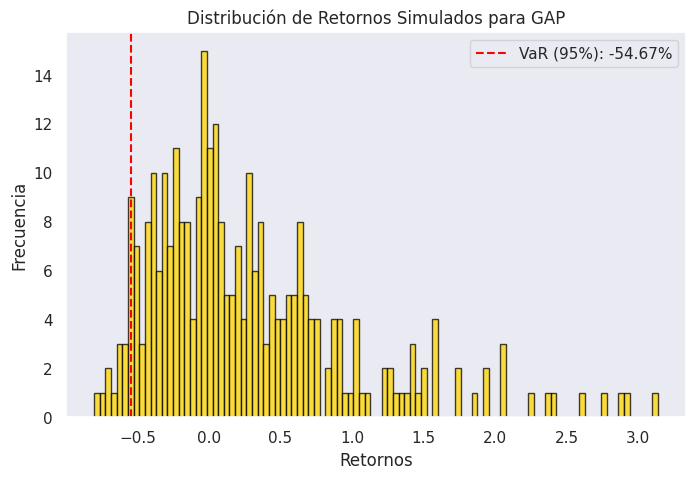


Resultados de VaR con Simulación de Monte Carlo:
- GAP: -54.67%


In [239]:


# ACCIONES PARA SIMULAR
acciones = ["TSLA", "AMZN", "GAP"]                                               # LISTA DE ACCIONES
start_date = "2023-12-10"                                                        # FECHA INICIO PARA 1 AÑO
end_date = "2024-12-10"                                                          # FECHA DE TERMINO PARA 1 AÑO

# PARAMETROS DE LA SIMULACIÓN
num_simulations = 300                                                            # NÚMERO DE SIMULACIONES
simulation_horizon = 252                                                         # DÍAS DE TRADING EN UN AÑO
initial_investment = 10_000_000                                                  # POSICIÓN INICIAL
confidence_level = 0.95                                                          # NIVEL DE CONFIANZA

# ALMACENAR LOS RESULTADOS DE VaR
VaR_results = {}

# ITERAR SOBRE CADA ACCIÓN
for accion in acciones:
    # DESCARGAR LOS DATOS DE LAS ACCIONES
    data = yf.download(accion, start=start_date, end=end_date, progress=False)

    # CALCULAR LOS RETORNOS LOGARÍTMICOS
    data["Returns"] = np.log(data["Close"] / data["Close"].shift(1))              # CALCULA RETORNOS LOGARITMICOS
    data.dropna(inplace=True)                                                     # ELIMINAR VALORES NULOS

    # GENERAR SIMULACIONES DE RETORNOS FUTUROS
    simulated_returns = np.random.normal(
        np.mean(data["Returns"]),                                                 # PROMEDIO DE RETORNOS HISTÓRICOS
        np.std(data["Returns"]),                                                  # DESVIACIÓN ESTÁNDAR DE RETORNOS
        (simulation_horizon, num_simulations)                                     # HORIZONTE Y NÚMERO DE SIMULACIONES
    )

    # SIMULAR LOS VALORES DEL PORTAFOLIO
    portfolio_values = initial_investment * np.exp(np.cumsum(simulated_returns, axis=0))  # VALORES FUTUROS

    # CALCULAR LOS RETORNOS FINALES DEL PORTAFOLIO
    portfolio_returns = portfolio_values[-1] / portfolio_values[0] - 1                    # RETORNOS AL FINAL DE CADA SIMULACIÓN

    # CALCULAR EL VaR AL 95% DE NIVEL DE CONFIANZA
    VaR_monte_carlo = np.percentile(portfolio_returns, (1 - confidence_level) * 100)      # NIVEL DE CONFIANZA

    # GUARDAR RESULTADOS
VaR_results[accion] = VaR_monte_carlo                                                                # GUARDA EL VALOR DE VaR CALCULADO PARA LA ACCIÓN ACTUAL EN UN DICCIONARIO

# PLOTEAR LA DISTRIBUCIÓN DE RETORNOS SIMULADOS
plt.figure(figsize=(8, 5))                                                                            # CREA UNA FIGURA DE TAMAÑO 8x5 PARA EL GRÁFICO
plt.hist(portfolio_returns, bins=100, alpha=0.75, color='gold', edgecolor='black')                    # GRAFICA UN HISTOGRAMA CON LOS RETORNOS SIMULADOS
plt.axvline(VaR_monte_carlo, color='red', linestyle='--', label=f'VaR (95%): {VaR_monte_carlo:.2%}')  # AGREGA UNA LÍNEA VERTICAL QUE REPRESENTA EL VaR
plt.title(f'Distribución de Retornos Simulados para {accion}')                                        # TITULO DEL GRÁFICO QUE INDICA LA ACCIÓN ANALIZADA
plt.xlabel('Retornos')                                                                                # ETIQUETA DEL EJE X: RETORNOS SIMULADOS
plt.ylabel('Frecuencia')                                                                              # ETIQUETA DEL EJE Y: FRECUENCIA DE LOS RETORNOS
plt.legend()                                                                                          # AGREGA UNA LEYENDA AL GRÁFICO
plt.show()                                                                                            # MUESTRA EL GRÁFICO EN PANTALLA

# MOSTRAR LOS RESULTADOS DE VaR PARA TODAS LAS ACCIONES
print("\nResultados de VaR con Simulación de Monte Carlo:")                                           # IMPRIME UN TÍTULO PARA LOS RESULTADOS
for accion, VaR in VaR_results.items():                                                               # ITERA SOBRE EL DICCIONARIO DE RESULTADOS (VaR DE CADA ACCIÓN)
    print(f"- {accion}: {VaR:.2%}")                                                                   # IMPRIME EL NOMBRE DE LA ACCIÓN Y SU VaR COMO PORCENTAJE


3 VAR MULTIVARIADO APLICACIONES CON PORTAFOLIO DE INVERSION

 CARACTERISTICAS DEL PORTAFOLIO

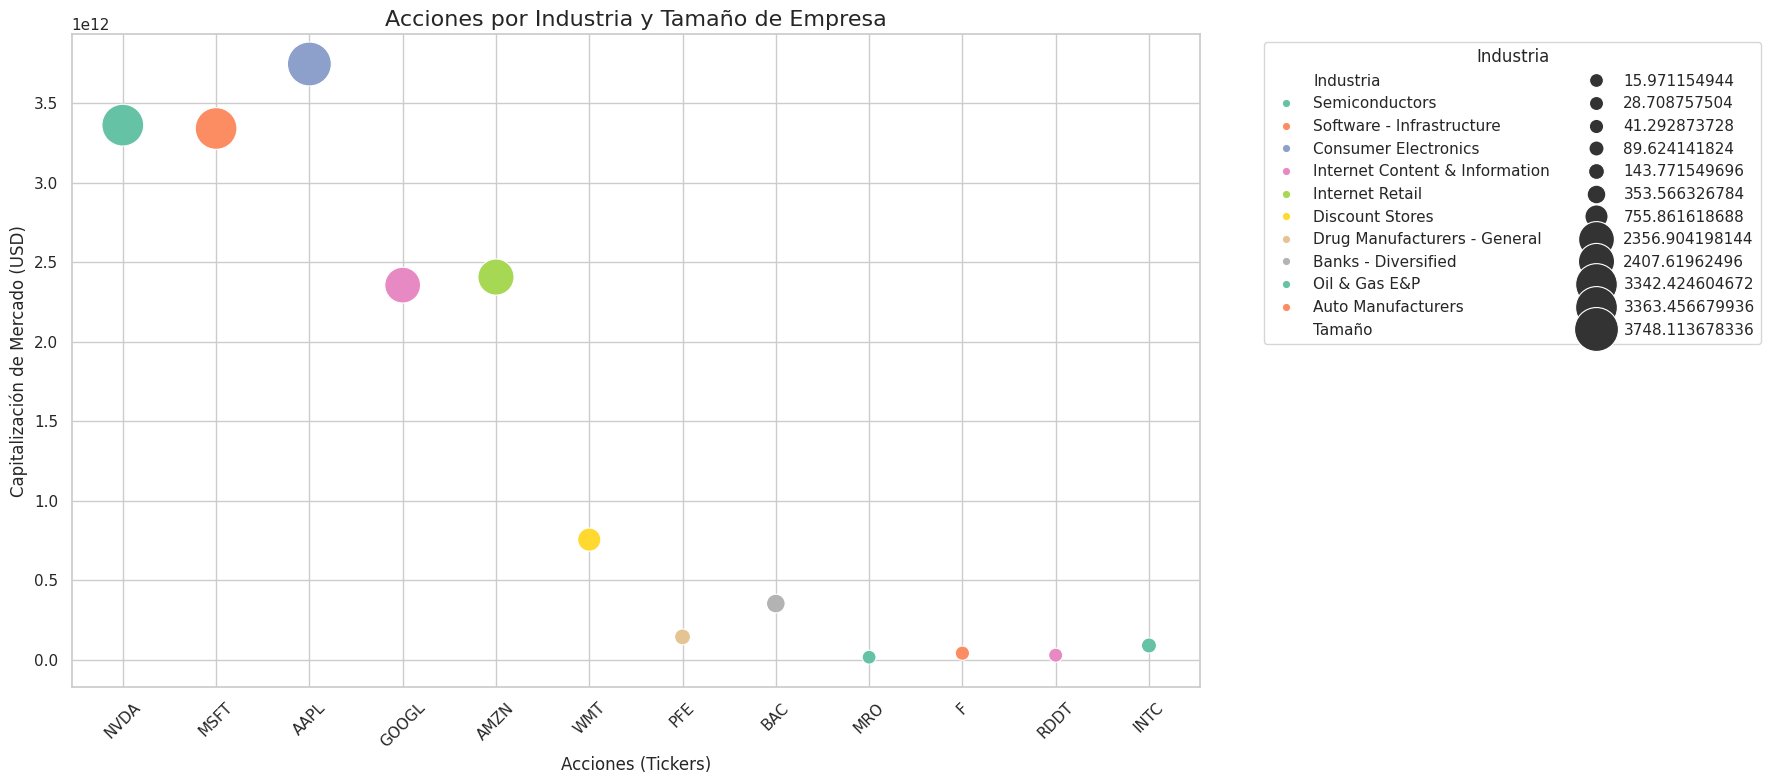

In [240]:
# LISTA DE ACCIONES
tickers = ["NVDA", "MSFT", "AAPL", "GOOGL", "AMZN", "WMT", "PFE", "BAC", "MRO", "F", "RDDT", "INTC"]

# INICIALIZAR DICCIONARIOS PARA ALMACENAR INDUSTRIAS Y CAPITALIZACIONES DE MERCADO
industry_info = {}                                                                                           # DICCIONARIO PARA GUARDAR LA INDUSTRIA DE CADA ACCIÓN
market_cap_data = {}                                                                                         # DICCIONARIO PARA GUARDAR LA CAPITALIZACIÓN DE MERCADO DE CADA ACCIÓN

# DESCARGAR DATOS PARA CADA TICKER
for ticker in tickers:                                                                                       # ITERAR SOBRE CADA TICKER EN LA LISTA
    try:
        stock_info = yf.Ticker(ticker).info                                                                  # OBTENER INFORMACIÓN DE LA ACCIÓN DESDE YAHOO FINANCE
        industry = stock_info.get("industry", "Desconocido")                                                 # OBTENER LA INDUSTRIA O ASIGNAR "DESCONOCIDO" SI NO HAY DATOS
        market_cap = stock_info.get("marketCap", 0)                                                          # OBTENER LA CAPITALIZACIÓN DE MERCADO O ASIGNAR 0 SI NO HAY DATOS

        # GUARDAR INFORMACIÓN SI ES VÁLIDA
        industry_info[ticker] = industry                                                                     # GUARDAR LA INDUSTRIA EN EL DICCIONARIO
        market_cap_data[ticker] = market_cap                                                                 # GUARDAR LA CAPITALIZACIÓN DE MERCADO EN EL DICCIONARIO

    except Exception as e:                                                                                   # MANEJAR ERRORES SI OCURREN
        print(f"Error al procesar {ticker}: {e}")                                                            # IMPRIMIR EL ERROR PARA SABER QUÉ PASÓ
        industry_info[ticker] = "Desconocido"                                                                # ASIGNAR "DESCONOCIDO" A LA INDUSTRIA SI HAY ERROR
        market_cap_data[ticker] = 0                                                                          # ASIGNAR 0 A LA CAPITALIZACIÓN DE MERCADO SI HAY ERROR

# FILTRAR SOLO TICKERS CON DATOS VÁLIDOS
valid_tickers = [ticker for ticker in tickers if market_cap_data[ticker] > 0]                                # INCLUIR SOLO TICKERS CON CAPITALIZACIÓN MAYOR A 0

# CREAR DATAFRAME PARA GRAFICAR
data = pd.DataFrame({                                                                                        # CREAR UNA TABLA CON LOS DATOS FILTRADOS
    "Ticker": valid_tickers,  # TICKERS VÁLIDOS
    "Industria": [industry_info[ticker] for ticker in valid_tickers],                                        # INDUSTRIAS ASOCIADAS A LOS TICKERS
    "Capitalización de Mercado (USD)": [market_cap_data[ticker] for ticker in valid_tickers]                 # CAPITALIZACIÓN DE MERCADO EN USD
})

# ASIGNAR TAMAÑO RELATIVO DE LOS PUNTOS BASADO EN LA CAPITALIZACIÓN DE MERCADO
data["Tamaño"] = data["Capitalización de Mercado (USD)"] / 1e9                                               # ESCALAR A MILES DE MILLONES PARA EL GRÁFICO

# CONFIGURAR ESTILO DE SEABORN
sns.set(style="whitegrid")                                                                                   # APLICAR UN ESTILO DE CUADRÍCULA BLANCA PARA EL GRÁFICO

# CREAR EL GRÁFICO DE DISPERSIÓN
plt.figure(figsize=(18, 8))                                                                                  # ESTABLECER EL TAMAÑO DE LA FIGURA
scatter = sns.scatterplot(                                                                                   # CREAR UN GRÁFICO DE DISPERSIÓN
    data=data,                                                                                               # USAR EL DATAFRAME CON LOS DATOS
    x="Ticker",                                                                                              # TICKERS EN EL EJE X
    y="Capitalización de Mercado (USD)",                                                                     # CAPITALIZACIÓN DE MERCADO EN EL EJE Y
    hue="Industria",                                                                                         # COLOR DE LOS PUNTOS BASADO EN LA INDUSTRIA
    size="Tamaño",                                                                                           # TAMAÑO DE LOS PUNTOS BASADO EN LA CAPITALIZACIÓN
    sizes=(100, 1000),                                                                                       # RANGO DE TAMAÑOS DE LOS PUNTOS (MÍNIMO Y MÁXIMO)
    palette="Set2",                                                                                          # PALETA DE COLORES PARA LAS INDUSTRIAS
    legend="full"                                                                                            # MOSTRAR LA LEYENDA COMPLETA
)

# CONFIGURAR ETIQUETAS Y TÍTULO
plt.title("Acciones por Industria y Tamaño de Empresa", fontsize=16)                                         # TÍTULO DEL GRÁFICO
plt.xlabel("Acciones (Tickers)", fontsize=12)                                                                # ETIQUETA DEL EJE X
plt.ylabel("Capitalización de Mercado (USD)", fontsize=12)                                                   # ETIQUETA DEL EJE Y
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Industria", ncol=2)                            # AJUSTAR LA LEYENDA AL LADO DERECHO
plt.xticks(rotation=45)                                                                                      # ROTAR LAS ETIQUETAS EN EL EJE X PARA MEJOR VISIBILIDAD
plt.grid(True)                                                                                               # MOSTRAR LA CUADRÍCULA EN EL GRÁFICO

# MOSTRAR EL GRÁFICO
plt.tight_layout()                                                                                           # AJUSTAR LOS MÁRGENES PARA QUE TODO QUEPA
plt.show()                                                                                                   # MOSTRAR EL GRÁFICO

3.A Y B CONSTRUCCION DE PORTAFOLIO CON 3% DE RENTABILIDAD Y FRONTERA EFICIENTE

[*********************100%***********************]  12 of 12 completed


NVDA: Exp. Ret = 0.0427, Risk = 0.0490
MSFT: Exp. Ret = 0.0270, Risk = 0.0607
AAPL: Exp. Ret = 0.0248, Risk = 0.0553
GOOGL: Exp. Ret = -0.0179, Risk = 0.0727
AMZN: Exp. Ret = 0.0183, Risk = 0.0483
WMT: Exp. Ret = -0.0679, Risk = 0.1481
PFE: Exp. Ret = 0.0032, Risk = 0.0482
BAC: Exp. Ret = 0.0087, Risk = 0.0596
MRO: Exp. Ret = 0.0528, Risk = 0.0994
F: Exp. Ret = 0.0004, Risk = 0.0731
RDDT: Exp. Ret = 0.1682, Risk = 0.2671
INTC: Exp. Ret = 0.0526, Risk = 0.0552

Optimal Portfolio
----------------------
Ponderación de NVDA: -0.00%
Ponderación de MSFT: 8.27%
Ponderación de AAPL: 0.00%
Ponderación de GOOGL: 0.00%
Ponderación de AMZN: 41.60%
Ponderación de WMT: 0.00%
Ponderación de PFE: -0.00%
Ponderación de BAC: 0.00%
Ponderación de MRO: -0.00%
Ponderación de F: 12.66%
Ponderación de RDDT: 0.35%
Ponderación de INTC: 37.12%
----------------------
Retorno esperado: 3.00%
Riesgo esperado: 2.58%


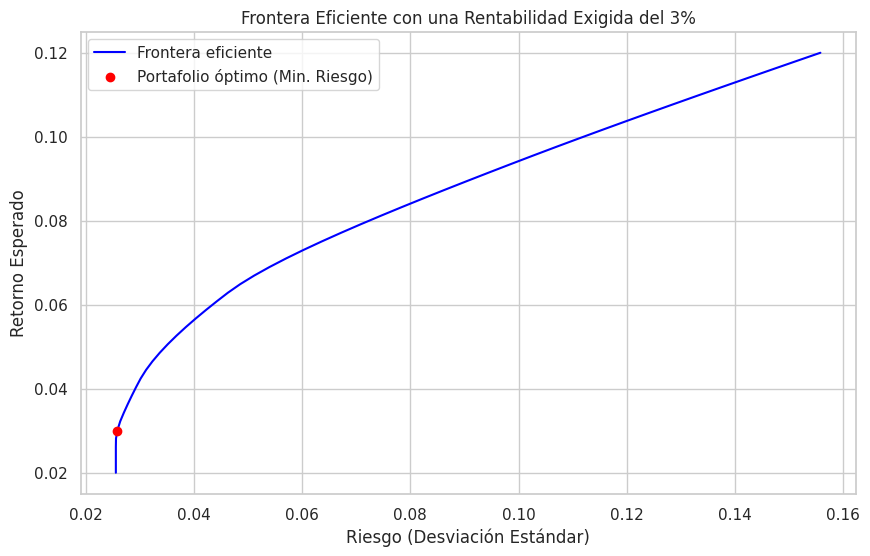

In [241]:

# TICKERS DE ACCIONES
tickers = ["NVDA", "MSFT", "AAPL", "GOOGL", "AMZN", "WMT", "PFE", "BAC", "MRO", "F", "RDDT", "INTC"]
# # LISTA DE LAS ACCIONES QUE ANALIZAREMOS.

# EXTRAEMOS DATOS DESDE YAHOO FINANCE PARA LOS TICKERS
data = yf.download(tickers, start='2019-01-01', end='2024-12-10')['Adj Close']
# # DESCARGAMOS EL PRECIO DE CIERRE AJUSTADO DE CADA ACCIÓN DESDE 2019 HASTA DICIEMBRE DE 2024.

# AGRUPAMOS LOS DATOS POR MESES Y TOMAMOS EL ÚLTIMO DÍA DEL MES
data = data.resample('M').last()
# # NOS ASEGURAMOS DE ANALIZAR DATOS MENSALES, EN VEZ DE DIARIOS.

# CALCULAMOS LOS RETORNOS MENSUALES
returns = data.pct_change().dropna()
# # USAMOS LA VARIACIÓN PORCENTUAL PARA OBTENER LOS RETORNOS MENSUALES DE CADA ACCIÓN.

# NOS ASEGURAMOS DE QUE "RETURNS" SEA UN DATAFRAME
if not isinstance(returns, pd.DataFrame):
    returns = pd.DataFrame(returns)
# # SI LOS RETORNOS NO ESTÁN EN FORMATO TABULAR, LOS CONVERTIMOS.

# CALCULAMOS LOS RETORNOS PROMEDIO ESPERADOS PARA CADA ACCIÓN
r = np.asarray(np.mean(returns, axis=0))
# # ESTIMAMOS LOS PROMEDIOS DE LOS RETORNOS PARA USARLOS EN EL MODELO.

# CALCULAMOS LA MATRIZ DE COVARIANZAS
C = np.cov(returns.to_numpy().T)
# # USAMOS LOS RETORNOS PARA CALCULAR CÓMO VARÍAN ENTRE SÍ LAS ACCIONES.

# IMPRIMIMOS LOS RETORNOS ESPERADOS Y LOS RIESGOS (DESVIACIÓN ESTÁNDAR)
for j in range(len(tickers)):
    print(f'{tickers[j]}: Exp. Ret = {r[j]:.4f}, Risk = {np.sqrt(C[j,j]):.4f}')
# # MOSTRAMOS LAS METRICAS CLAVE DE CADA ACCIÓN.

# DEFINIMOS EL NÚMERO DE VARIABLES (ACCIONES)
n = len(tickers)
# # LA CANTIDAD DE ACCIONES EN NUESTRO PORTAFOLIO.

# DEFINIMOS UNA VARIABLE PARA LAS PONDERACIONES DE CADA ACCIÓN
x = cv.Variable(n)
# # "X" REPRESENTA LAS PROPORCIONES DE INVERSIÓN EN CADA ACCIÓN.

# FIJAMOS UNA RENTABILIDAD MÍNIMA EXIGIDA
req_return = 0.03
# # EL PORTAFOLIO DEBE OFRECER AL MENOS UN 3% DE RETORNO ESPERADO.

# DEFINIMOS LA FUNCIÓN DE RETORNO Y RIESGO
ret = r.T @ x
risk = cv.quad_form(x, C)
# # "RET" ES EL RETORNO DEL PORTAFOLIO Y "RISK" ES EL RIESGO (USAMOS LA MATRIZ DE COVARIANZAS).

# FORMULAMOS EL PROBLEMA DE OPTIMIZACIÓN
constraints = [cv.sum(x) == 1, x >= 0, ret >= req_return]
objective = cv.Minimize(risk)
problem = cv.Problem(objective, constraints)
# # BUSCAMOS MINIMIZAR EL RIESGO, SUJETO A QUE LAS PONDERACIONES SUMEN 1, SEAN POSITIVAS Y EL RETORNO SEA ≥ 3%.

# RESOLVEMOS EL PROBLEMA
problem.solve()
# # UTILIZAMOS UNA FUNCIÓN MATEMÁTICA PARA ENCONTRAR LA MEJOR SOLUCIÓN.

# VALIDAMOS SI SE ENCONTRÓ UNA SOLUCIÓN
if x.value is None:
    raise ValueError("No se pudo encontrar una solución óptima para el problema.")
# # MOSTRAMOS UN ERROR SI NO SE PUDO RESOLVER EL MODELO.

# MOSTRAMOS LOS RESULTADOS
optimal_weights = x.value
print("\nOptimal Portfolio")
print("----------------------")
for i in range(len(tickers)):
    print(f'Ponderación de {tickers[i]}: {optimal_weights[i] * 100:.2f}%')
print("----------------------")
print(f'Retorno esperado: {ret.value * 100:.2f}%')
print(f'Riesgo esperado: {np.sqrt(risk.value) * 100:.2f}%')
# # IMPRIMIMOS LAS PONDERACIONES DE INVERSIÓN Y LOS VALORES DE RETORNO Y RIESGO DEL PORTAFOLIO.

# FUNCIÓN PARA GENERAR LA FRONTERA EFICIENTE
def efficient_frontier(mu, Sigma, return_range):
    risks = []
    returns = []
    for target_return in return_range:
        w = cv.Variable(mu.shape[0])
        risk = cv.quad_form(w, Sigma)
        constraints = [cv.sum(w) == 1, w >= 0, mu @ w >= target_return]
        problem = cv.Problem(cv.Minimize(risk), constraints)
        problem.solve()
        if w.value is None:
            continue
        risks.append(np.sqrt(risk.value))
        returns.append(target_return)
    return risks, returns
# # ESTA FUNCIÓN GENERA DIFERENTES PORTAFOLIOS ÓPTIMOS CON DISTINTOS NIVELES DE RETORNO.

# GENERAMOS DATOS PARA LA FRONTERA EFICIENTE
mu = np.mean(returns.to_numpy(), axis=0)  # # LOS PROMEDIOS DE LOS RETORNOS.
Sigma = np.cov(returns.to_numpy().T)      # # LA MATRIZ DE COVARIANZAS.
return_range = np.linspace(0.02, 0.12, 50)  # # NIVELES DE RETORNO ENTRE EL 2% Y EL 12%.
risks, returns = efficient_frontier(mu, Sigma, return_range)
# # CALCULAMOS LOS RIESGOS Y RETORNOS PARA LA FRONTERA.

# GRAFICAMOS LA FRONTERA EFICIENTE
plt.figure(figsize=(10, 6))
plt.plot(risks, returns, label='Frontera eficiente', color='blue')
plt.scatter(np.sqrt(risk.value), req_return, color='red', label='Portafolio óptimo (Min. Riesgo)', zorder=5)
plt.title('Frontera Eficiente con una Rentabilidad Exigida del 3%')
plt.xlabel('Riesgo (Desviación Estándar)')
plt.ylabel('Retorno Esperado')
plt.legend()
plt.grid(True)
plt.show()
# # DIBUJAMOS LA GRÁFICA DE LA FRONTERA EFICIENTE, DESTACANDO EL PORTAFOLIO ÓPTIMO.



GRAFICO DE PORTAFOLIO OPTIMIZADO PARA COMENZAR LAS SIMULACIONES

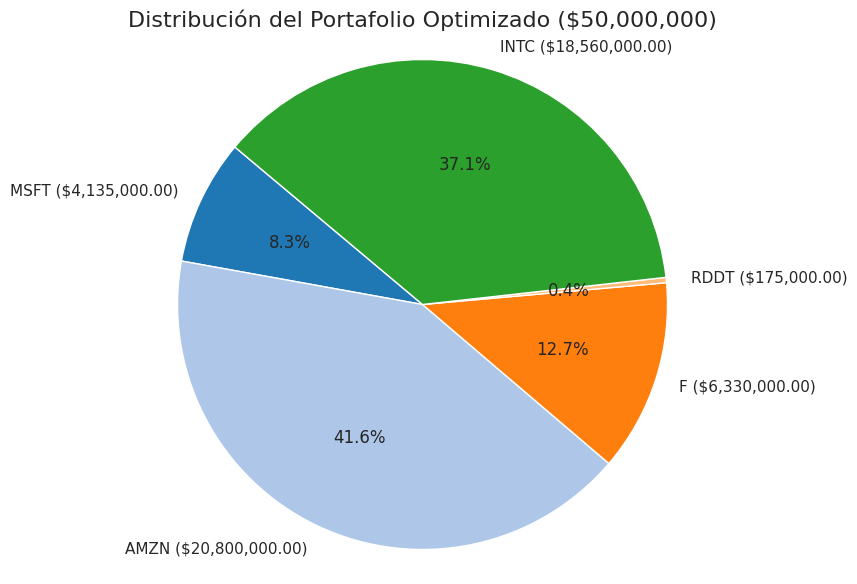

In [242]:
# DATOS DEL PORTAFOLIO OPTIMIZADO
portfolio = {
    "MSFT": 0.0827,
    "AMZN": 0.4160,
    "F": 0.1266,
    "RDDT": 0.0035,
    "INTC": 0.3712
}

# MONTO TOTAL DEL PORTAFOLIO
total_amount = 50000000

# CALCULAR LA DISTRIBUCIÓN EN DINERO
portfolio_money = {key: value * total_amount for key, value in portfolio.items()}               # MULTIPLICAR LAS PONDERACIONES POR EL MONTO TOTAL PARA OBTENER LA CANTIDAD EN DINERO

# FILTRAR ACCIONES CON PONDERACIÓN MAYOR A 0
portfolio_filtered = {key: value for key, value in portfolio.items() if value > 0}              # FILTRAR SOLO LAS ACCIONES QUE TIENEN PONDERACIONES POSITIVAS
portfolio_money_filtered = {key: value for key, value in portfolio_money.items() if value > 0}  # FILTRAR LAS CANTIDADES EN DINERO PARA ACCIONES CON PONDERACIONES POSITIVAS

# CREAR EL GRÁFICO DE TORTA
labels = list(portfolio_filtered.keys())                                                        # EXTRAER LOS TICKERS COMO ETIQUETAS PARA EL GRÁFICO
sizes = list(portfolio_filtered.values())                                                       # OBTENER LAS PONDERACIONES COMO TAMAÑOS PARA EL GRÁFICO
money_labels = [f"{label} (${portfolio_money_filtered[label]:,.2f})" for label in labels]       # CREAR ETIQUETAS QUE INCLUYAN LOS TICKERS Y LAS CANTIDADES EN DINERO

plt.figure(figsize=(10, 7))                                                                     # DEFINIR EL TAMAÑO DEL GRÁFICO
plt.pie(
    sizes,                                                                                      # USAR LAS PONDERACIONES COMO TAMAÑOS DE LAS SECCIONES
    labels=money_labels,                                                                        # USAR LAS ETIQUETAS QUE INCLUYEN TICKERS Y DINERO
    autopct='%1.1f%%',                                                                          # MOSTRAR LOS PORCENTAJES EN CADA SECCIÓN
    startangle=140,                                                                             # COMENZAR EL GRÁFICO DESDE UN ÁNGULO DE 140 GRADOS
    colors=plt.cm.tab20.colors                                                                  # USAR UNA PALETA DE COLORES PREDIFINIDA (TAB20)
)
plt.title("Distribución del Portafolio Optimizado ($50,000,000)", fontsize=16)                  # AGREGAR UN TÍTULO AL GRÁFICO
plt.axis('equal')                                                                               # ASEGURAR QUE EL GRÁFICO SEA CIRCULAR Y NO ELÍPTICO
plt.show()                                                                                      # MOSTRAR EL GRÁFICO

3 - C VaR  CON $50.000.000 AL 99% CON DATOS HISTORICOS

VaR Histórico al 99% para MSFT: -143,981.44 USD
VaR Histórico al 99% para AMZN: -874,671.27 USD
VaR Histórico al 99% para F: -435,944.62 USD
VaR Histórico al 99% para RDDT: -15,074.12 USD
VaR Histórico al 99% para INTC: -1,727,128.07 USD


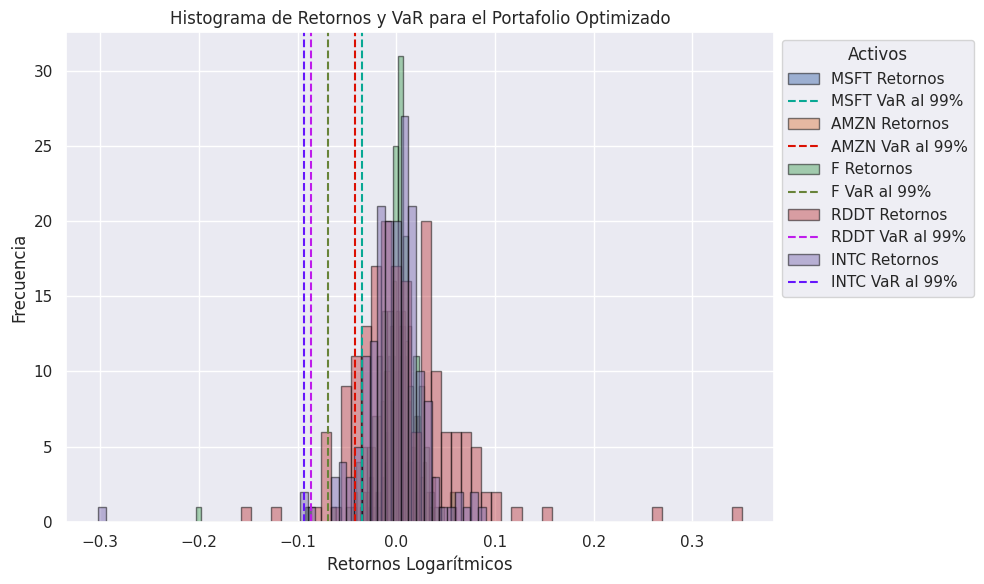

In [243]:

warnings.simplefilter("ignore")                                                  # IGNORAR ADVERTENCIAS
sns.set_style('dark')                                                            # CONFIGURAR ESTILO OSCURO

# DATOS DEL PORTAFOLIO OPTIMIZADO
portfolio_weights = {
    "MSFT": 0.0827,
    "AMZN": 0.4160,
    "F": 0.1266,
    "RDDT": 0.0035,
    "INTC": 0.3712
}

# DEFINIR ACTIVOS Y PARÁMETROS
tickers = list(portfolio_weights.keys())                                         # SELECCIONAR SOLO TICKERS CON PESOS DEFINIDOS
start_date = '2023-12-10'                                                        # FECHA INICIAL
end_date = '2024-12-10'                                                          # FECHA FINAL
position = 50000000                                                              # TAMAÑO TOTAL DEL PORTAFOLIO
confidence_level = 0.99                                                          # NIVEL DE CONFIANZA PARA EL VaR

# DESCARGAR DATOS HISTÓRICOS
data = yf.download(tickers, start=start_date, end=end_date, progress=False)

# CALCULAR RETORNOS LOGARÍTMICOS
returns = np.log(data['Close'] / data['Close'].shift(1))
returns.dropna(inplace=True)

# CALCULAR VaR HISTÓRICO PARA CADA ACTIVO (AJUSTADO POR PESOS DEL PORTAFOLIO)
var_historical = {}
for ticker in tickers:
    if portfolio_weights[ticker] > 0:                                                    # SOLO CONSIDERAR TICKERS CON PESOS POSITIVOS
        var_percentile = np.percentile(returns[ticker], (1 - confidence_level) * 100)    # PERCENTIL DEL VaR
        var_dollars = var_percentile * position * portfolio_weights[ticker]              # AJUSTAR POR PESO Y POSICIÓN TOTAL
        var_historical[ticker] = var_dollars                                             # GUARDAR RESULTADO
        print(f"VaR Histórico al {confidence_level*100:.0f}% para {ticker}: {var_dollars:,.2f} USD")

plt.figure(figsize=(10, 6))                                                              # CREA UNA FIGURA DE TAMAÑO 10x6 PARA EL GRÁFICO

for ticker in tickers:                                                                   # ITERA SOBRE CADA ACCIÓN (TICKER) EN LA LISTA `tickers`
    if portfolio_weights[ticker] > 0:                                                    # SOLO INCLUIR TICKERS CON PONDERACIÓN MAYOR A 0 EN EL PORTAFOLIO
        plt.hist(                                                                        # GRAFICAR EL HISTOGRAMA DE LOS RETORNOS DEL TICKER ACTUAL
            returns[ticker],                                                             # USAR LOS RETORNOS DE LA ACCIÓN ACTUAL
            bins=50,                                                                     # AGRUPAR LOS DATOS EN 50 BARRAS
            alpha=0.5,                                                                   # AJUSTAR LA TRANSPARENCIA DEL HISTOGRAMA
            label=f'{ticker} Retornos',                                                  # ETIQUETAR CON EL NOMBRE DEL TICKER
            edgecolor='black'                                                            # AGREGAR BORDES NEGROS A LAS BARRAS
        )
        var_value = np.percentile(                                                       # CALCULAR EL VaR (VALOR EN RIESGO) DEL TICKER
            returns[ticker],                                                             # USAR LOS RETORNOS DE LA ACCIÓN ACTUAL
            (1 - confidence_level) * 100                                                 # CALCULAR EL PERCENTIL PARA EL NIVEL DE CONFIANZA
        )
        plt.axvline(                                                                     # AGREGAR UNA LÍNEA VERTICAL QUE REPRESENTE EL VaR
            var_value,                                                                   # POSICIÓN DE LA LÍNEA (EL VALOR DEL VaR)
            linestyle='--',                                                              # LÍNEA DISCONTINUA
            label=f'{ticker} VaR al {confidence_level*100:.0f}%',                        # ETIQUETA PARA LA LÍNEA
            color=np.random.rand(3,)                                                     # ASIGNAR UN COLOR ALEATORIO
        )

# CONFIGURACIONES DEL GRÁFICO
plt.title('Histograma de Retornos y VaR para el Portafolio Optimizado')                  # TÍTULO DEL GRÁFICO
plt.xlabel('Retornos Logarítmicos')                                                      # ETIQUETA DEL EJE X
plt.ylabel('Frecuencia')                                                                 # ETIQUETA DEL EJE Y
plt.legend(                                                                              # AGREGAR UNA LEYENDA AL GRÁFICO
    loc='upper left',                                                                    # COLOCAR LA LEYENDA EN LA ESQUINA SUPERIOR IZQUIERDA
    bbox_to_anchor=(1, 1),                                                               # MOVER LA LEYENDA HACIA FUERA DEL GRÁFICO
    title='Activos'                                                                      # TÍTULO DE LA LEYENDA
)
plt.grid(True)                                                                           # AGREGAR UNA CUADRÍCULA EN EL GRÁFICO
plt.tight_layout()                                                                       # AJUSTAR AUTOMÁTICAMENTE LOS MÁRGENES DEL GRÁFICO
plt.show()                                                                               # MOSTRAR EL GRÁFICO EN PANTALLA



3.D VAR CON $50.000.000 AL 99% CON VARIANZA CONSTANTE GJR GARCH


Forecast de VaR a 5 días (Portafolio Optimizado):
              Día 1          Día 2          Día 3          Día 4  \
MSFT  -84693.504729  -84729.513583  -84765.507140  -84801.485420   
AMZN -437267.602301 -435918.604826 -434624.385356 -433382.861842   
F    -131560.911496 -131562.546923 -131564.143033 -131565.700772   
RDDT   -3254.004579   -3268.163569   -3269.024797   -3269.077295   
INTC -370106.286969 -374241.790444 -377131.323461 -379156.091559   

              Día 5  
MSFT  -84837.448443  
AMZN -432192.020775  
F    -131567.221064  
RDDT   -3269.080496  
INTC -380577.698618  


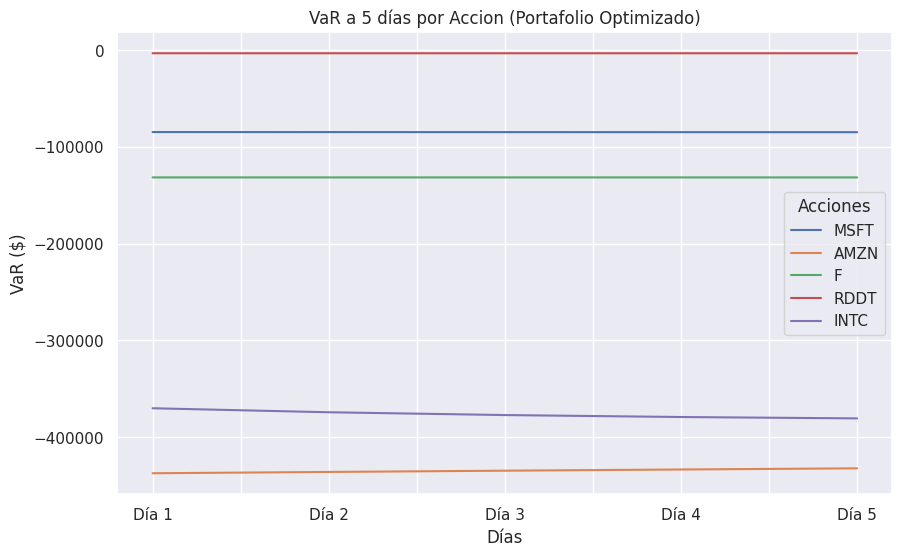

In [244]:
# DATOS DEL PORTAFOLIO OPTIMIZADO (PONDERACIONES)
portfolio_weights = {
    "MSFT": 0.0827,
    "AMZN": 0.4160,
    "F": 0.1266,
    "RDDT": 0.0035,
    "INTC": 0.3712
}
# LISTA DE TICKERS PARA ANALIZAR (CON PESOS MAYORES A 0)
tickers = [ticker for ticker, weight in portfolio_weights.items() if weight > 0]

# PARÁMETROS PRINCIPALES
confidence_level = 0.99                                                                          # NIVEL DE CONFIANZA (99%)
position = 50000000                                                                              # TAMAÑO DE LA INVERSIÓN (EN DÓLARES)
forecast_days = 5                                                                                # HORIZONTE DE PRONÓSTICO (DÍAS)

# SIMULACIÓN: GENERAR RETORNOS ALEATORIOS PARA CADA TICKER (SI NO TIENES DATOS REALES)
np.random.seed(42)                                                                               # PARA RESULTADOS REPRODUCIBLES
returns = pd.DataFrame({
    ticker: np.random.normal(0, 0.02, 252) for ticker in tickers                                 # 252 DÍAS DE RETORNOS SIMULADOS POR TICKER
})

# RESULTADOS DEL PRONÓSTICO
forecast_results = {}                                                                            # DICCIONARIO PARA ALMACENAR LOS RESULTADOS

# BUCLE PARA CALCULAR EL VaR PARA CADA TICKER
for ticker in tickers:
    try:
        # AJUSTAR EL MODELO GARCH PARA EL TICKER
        result = arch_model(returns[ticker] * 100, vol='GARCH', p=1, q=1, o=1).fit(disp="off")

        # PRONOSTICAR LA VOLATILIDAD
        forecast_volatility = result.forecast(horizon=forecast_days).variance.values[-1] ** 0.5 / 100

        # CALCULAR EL VaR AJUSTADO POR EL PESO DEL PORTAFOLIO
        var_values = -forecast_volatility * position * portfolio_weights[ticker]

        # GUARDAR RESULTADOS
        forecast_results[ticker] = var_values
    except Exception as e:
        print(f"Error al procesar {ticker}: {e}")

# CONVERTIR LOS RESULTADOS EN UN DATAFRAME
forecast_df = pd.DataFrame.from_dict(forecast_results, orient='index', columns=[f'Día {i+1}' for i in range(forecast_days)])

# MOSTRAR RESULTADOS EN CONSOLA
print("\nForecast de VaR a 5 días (Portafolio Optimizado):")
print(forecast_df)

# GRAFICAR LOS RESULTADOS
forecast_df.T.plot(figsize=(10, 6), title='VaR a 5 días por Accion (Portafolio Optimizado)', xlabel='Días', ylabel='VaR ($)')
plt.legend(title='Acciones')
plt.grid()
plt.show()

3 E - SIMULACION DE MONTECARLO Y VAR   CON DSITRIBUCION DE LOS RETORNOS

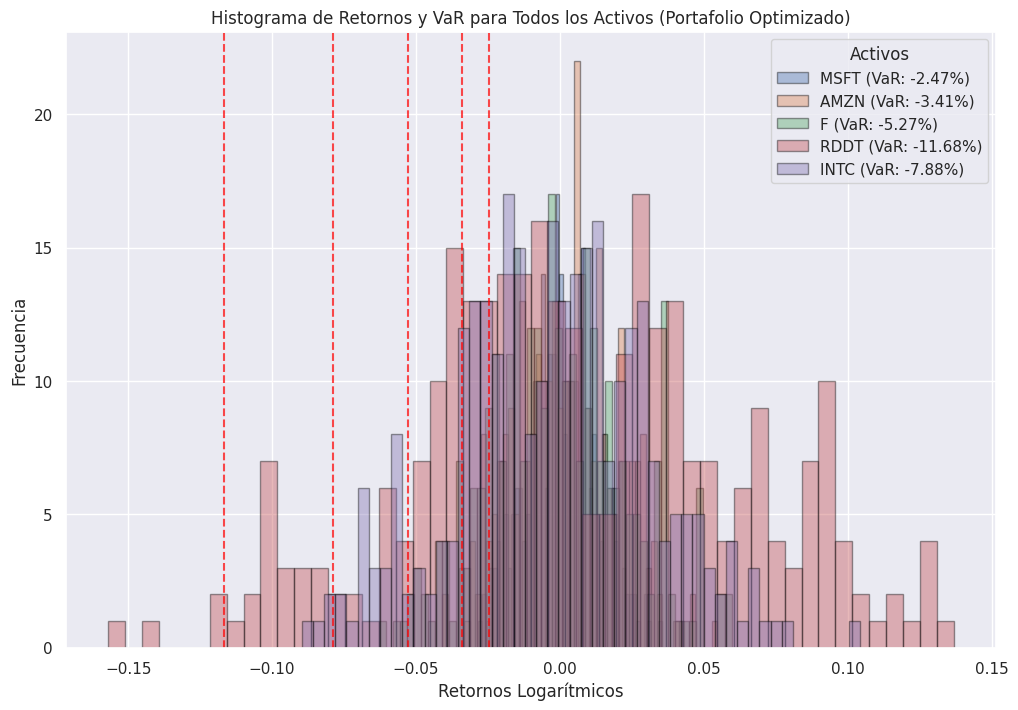


Detalles de VaR para Cada Acción (Portafolio Optimizado):
- MSFT: VaR (99%): -2.47%, Pérdida en Dinero: $-102,303.71
- AMZN: VaR (99%): -3.41%, Pérdida en Dinero: $-708,654.32
- F: VaR (99%): -5.27%, Pérdida en Dinero: $-333,882.63
- RDDT: VaR (99%): -11.68%, Pérdida en Dinero: $-20,445.07
- INTC: VaR (99%): -7.88%, Pérdida en Dinero: $-1,462,529.42

Resultado del VaR para el Portafolio Completo:
- VaR (99%): -51.66%, Pérdida en Dinero: $-25,830,098.01


In [245]:

# DATOS DEL PORTAFOLIO OPTIMIZADO (PONDERACIONES)
portfolio_weights = {
    "MSFT": 0.0827,
    "AMZN": 0.4160,
    "F": 0.1266,
    "RDDT": 0.0035,
    "INTC": 0.3712
}

# LISTA DE TICKERS PARA SIMULAR (CON PESOS POSITIVOS)
acciones = [accion for accion, peso in portfolio_weights.items() if peso > 0]                          # FILTRAR SOLO TICKERS CON PONDERACIONES MAYORES A 0

# PARÁMETROS DE LA SIMULACIÓN
start_date = "2023-12-10"                                                                              # FECHA INICIAL PARA LOS DATOS
end_date = "2024-12-10"                                                                                # FECHA FINAL PARA LOS DATOS
num_simulations = 300                                                                                  # NÚMERO DE SIMULACIONES A REALIZAR
simulation_horizon = 252                                                                               # NÚMERO DE DÍAS EN EL HORIZONTE DE SIMULACIÓN (DÍAS DE TRADING)
initial_investment = 50000000                                                                          # INVERSIÓN INICIAL TOTAL EN EL PORTAFOLIO (USD)
confidence_level = 0.99                                                                                # NIVEL DE CONFIANZA PARA EL CÁLCULO DEL VaR (99%)
delta_t = 1 / simulation_horizon                                                                       # INTERVALO DE TIEMPO (1 DÍA DE TRADING)

# ALMACENAR RESULTADOS DE VaR
VaR_results = {}                                                                                       # DICCIONARIO PARA GUARDAR EL VaR DE CADA ACCIÓN
portfolio_aggregated_values = np.zeros((simulation_horizon, num_simulations))                          # MATRIZ PARA LOS VALORES AGREGADOS DEL PORTAFOLIO
portfolio_aggregated_values[0] = initial_investment                                                    # ASIGNAR LA INVERSIÓN INICIAL AL PRIMER DÍA
individual_VaR_details = []                                                                            # LISTA PARA GUARDAR LOS DETALLES DEL VaR DE CADA ACCIÓN

# CREAR UNA FIGURA PARA TODOS LOS GRÁFICOS
plt.figure(figsize=(12, 8))                                                                            # CREAR UNA FIGURA DE TAMAÑO 12x8 PARA LOS GRÁFICOS

# ITERAR SOBRE CADA ACCIÓN Y AGREGAR AL PORTAFOLIO
for accion in acciones:                                                                                # ITERAR SOBRE LOS TICKERS CON PESOS POSITIVOS
    # DESCARGAR LOS DATOS DE LAS ACCIONES
    data = yf.download(accion, start=start_date, end=end_date, progress=False)                         # OBTENER DATOS DE YAHOO FINANCE

    # CALCULAR LOS RETORNOS LOGARÍTMICOS
    data["Returns"] = np.log(data["Close"] / data["Close"].shift(1))                                   # CALCULAR LOS RETORNOS LOGARÍTMICOS
    data.dropna(inplace=True)                                                                          # ELIMINAR FILAS CON DATOS NULOS

    # CALCULAR LOS PARÁMETROS DEL GBM
    mu = np.mean(data["Returns"])                                                                      # PROMEDIO DE LOS RETORNOS
    sigma = np.std(data["Returns"])                                                                    # DESVIACIÓN ESTÁNDAR DE LOS RETORNOS

    # GENERAR SIMULACIONES USANDO GBM
    portfolio_values = np.zeros((simulation_horizon, num_simulations))                                 # MATRIZ PARA LOS VALORES SIMULADOS
    portfolio_values[0] = initial_investment * portfolio_weights[accion]                               # AJUSTAR LA INVERSIÓN INICIAL POR EL PESO

    for t in range(1, simulation_horizon):                                                             # ITERAR SOBRE LOS DÍAS DE TRADING
        Z = np.random.normal(0, 1, num_simulations)                                                    # GENERAR NÚMEROS ALEATORIOS NORMALES
        portfolio_values[t] = portfolio_values[t - 1] * np.exp((mu - 0.5 * sigma**2) * delta_t + sigma * np.sqrt(delta_t) * Z)

    # AGREGAR LOS VALORES AL PORTAFOLIO AGREGADO
    portfolio_aggregated_values += portfolio_values                                                    # SUMAR LOS VALORES AL PORTAFOLIO TOTAL

    # CALCULAR LOS RETORNOS FINALES DE LA ACCIÓN
    portfolio_returns = portfolio_values[-1] / portfolio_values[0] - 1                                 # CALCULAR LOS RETORNOS AL FINAL

    # CALCULAR EL VaR INDIVIDUAL PARA LA ACCIÓN
    VaR_individual = np.percentile(portfolio_returns, (1 - confidence_level) * 100)                    # CALCULAR EL VaR (PERCENTIL)
    VaR_results[accion] = VaR_individual                                                               # GUARDAR EL VaR EN EL DICCIONARIO

    # DETALLES INDIVIDUALES DEL VaR
    VaR_amount = VaR_individual * (initial_investment * portfolio_weights[accion])                     # CALCULAR LA PÉRDIDA EN DINERO
    individual_VaR_details.append((accion, VaR_individual, VaR_amount))                                # GUARDAR LOS DETALLES EN LA LISTA

    # AGREGAR LA DISTRIBUCIÓN AL GRÁFICO
    plt.hist(portfolio_returns, bins=50, alpha=0.4, label=f'{accion} (VaR: {VaR_individual:.2%})', edgecolor='black')  # GRAFICAR EL HISTOGRAMA
    plt.axvline(VaR_individual, color='red', linestyle='--', alpha=0.7)                                                # AGREGAR UNA LÍNEA PARA EL VaR

# CONFIGURAR EL GRÁFICO GLOBAL
plt.title('Histograma de Retornos y VaR para Todos los Activos (Portafolio Optimizado)')  # TÍTULO DEL GRÁFICO
plt.xlabel('Retornos Logarítmicos')                                                       # ETIQUETA DEL EJE X
plt.ylabel('Frecuencia')                                                                  # ETIQUETA DEL EJE Y
plt.legend(title='Activos')                                                               # AGREGAR UNA LEYENDA
plt.grid(True)                                                                            # MOSTRAR CUADRÍCULA
plt.show()                                                                                # MOSTRAR EL GRÁFICO

# CALCULAR EL VaR DEL PORTAFOLIO COMPLETO
portfolio_aggregated_returns = portfolio_aggregated_values[-1] / portfolio_aggregated_values[0] - 1                    # CALCULAR LOS RETORNOS DEL PORTAFOLIO
VaR_portfolio = np.percentile(portfolio_aggregated_returns, (1 - confidence_level) * 100)                              # CALCULAR EL VaR TOTAL
VaR_portfolio_amount = VaR_portfolio * initial_investment                                                              # CALCULAR LA PÉRDIDA TOTAL EN DINERO

# MOSTRAR LOS RESULTADOS DETALLADOS
print("\nDetalles de VaR para Cada Acción (Portafolio Optimizado):")                                                   # MENSAJE INFORMATIVO
for accion, VaR_individual, VaR_amount in individual_VaR_details:                                                      # ITERAR SOBRE LOS RESULTADOS INDIVIDUALES
    print(f"- {accion}: VaR (99%): {VaR_individual:.2%}, Pérdida en Dinero: ${VaR_amount:,.2f}")                       # IMPRIMIR DETALLES DEL VaR

# MOSTRAR LOS RESULTADOS DE VaR PARA EL PORTAFOLIO COMPLETO
print("\nResultado del VaR para el Portafolio Completo:")                                                              # MENSAJE INFORMATIVO
print(f"- VaR (99%): {VaR_portfolio:.2%}, Pérdida en Dinero: ${VaR_portfolio_amount:,.2f}")                            # IMPRIMIR EL VaR TOTAL





E 3.1 SIMULACION DE MONTE CARLO PROYECCION DE GANANCIAS

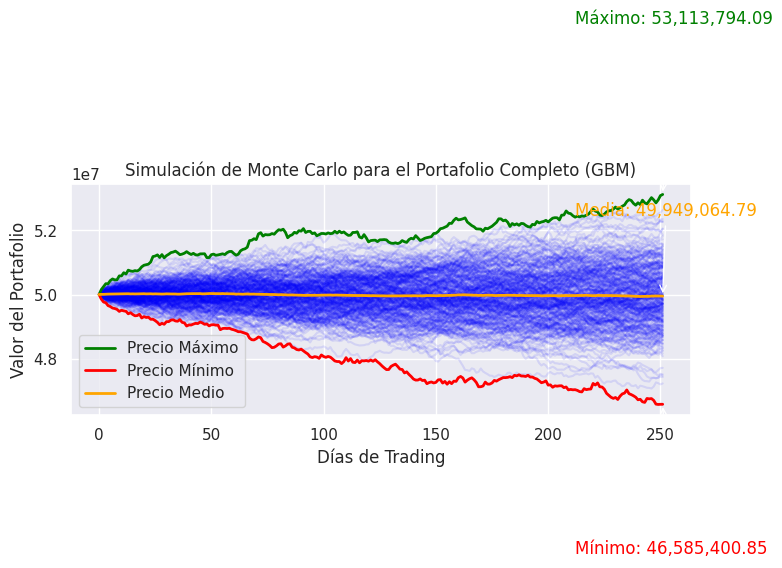

In [246]:
# DATOS DEL PORTAFOLIO OPTIMIZADO (PONDERACIONES)
portfolio_weights = {
    "MSFT": 0.0827,
    "AMZN": 0.4160,
    "F": 0.1266,
    "RDDT": 0.0035,
    "INTC": 0.3712
}

# FILTRAR ACCIONES CON PESOS POSITIVOS
acciones = [accion for accion, peso in portfolio_weights.items() if peso > 0]     # INCLUIR SOLO ACCIONES CON PONDERACIONES MAYORES A 0

# PARÁMETROS DE LA SIMULACIÓN
start_date = "2023-12-10"                                                         # FECHA INICIAL DE LOS DATOS
end_date = "2024-12-10"                                                           # FECHA FINAL DE LOS DATOS
num_simulations = 300                                                             # NÚMERO DE SIMULACIONES A REALIZAR
simulation_horizon = 252                                                          # NÚMERO DE DÍAS DE TRADING EN UN AÑO
initial_investment = 50000000                                                     # INVERSIÓN INICIAL TOTAL DEL PORTAFOLIO (USD)
confidence_level = 0.99                                                           # NIVEL DE CONFIANZA PARA EL CÁLCULO DEL VaR
delta_t = 1 / simulation_horizon                                                  # INTERVALO DE TIEMPO ENTRE SIMULACIONES

# DESCARGAR DATOS HISTÓRICOS Y ALINEAR RETORNOS
portfolio_returns = []                                                             # LISTA PARA GUARDAR LOS RETORNOS PONDERADOS
for accion in acciones:                                                            # ITERAR SOBRE CADA ACCIÓN
    data = yf.download(accion, start=start_date, end=end_date, progress=False)     # DESCARGAR DATOS HISTÓRICOS
    data["Returns"] = np.log(data["Close"] / data["Close"].shift(1))               # CALCULAR LOS RETORNOS LOGARÍTMICOS
    data.dropna(inplace=True)                                                      # ELIMINAR FILAS CON DATOS NULOS
    portfolio_returns.append(data["Returns"] * portfolio_weights[accion])          # MULTIPLICAR LOS RETORNOS POR LA PONDERACIÓN DE LA ACCIÓN

# ALINEAR Y SUMAR LOS RETORNOS PONDERADOS
portfolio_returns = pd.concat(portfolio_returns, axis=1).sum(axis=1)               # SUMAR LOS RETORNOS PONDERADOS DE CADA ACCIÓN

# CALCULAR RETORNO Y VOLATILIDAD AGREGADOS DEL PORTAFOLIO
mu_portfolio = np.mean(portfolio_returns)                                          # CALCULAR EL RETORNO PROMEDIO DEL PORTAFOLIO
sigma_portfolio = np.std(portfolio_returns)                                        # CALCULAR LA DESVIACIÓN ESTÁNDAR (VOLATILIDAD) DEL PORTAFOLIO

# GENERAR SIMULACIONES USANDO GBM
portfolio_values = np.zeros((simulation_horizon, num_simulations))                 # MATRIZ PARA GUARDAR LOS VALORES DEL PORTAFOLIO
portfolio_values[0] = initial_investment                                           # INICIALIZAR CON LA INVERSIÓN TOTAL

for t in range(1, simulation_horizon):                                             # ITERAR SOBRE CADA DÍA DE SIMULACIÓN
    Z = np.random.normal(0, 1, num_simulations)                                    # GENERAR NÚMEROS ALEATORIOS NORMALES
    portfolio_values[t] = portfolio_values[t - 1] * np.exp(                        # CALCULAR LOS VALORES USANDO EL MODELO GBM
        (mu_portfolio - 0.5 * sigma_portfolio**2) * delta_t +                      # COMPONENTE DRIFT
        sigma_portfolio * np.sqrt(delta_t) * Z                                     # COMPONENTE ESTOCÁSTICO
    )

# GRAFICAR LAS SIMULACIONES
plt.figure(figsize=(8, 3))                                                        # CREAR UNA FIGURA DE TAMAÑO 12x8
for i in range(num_simulations):                                                   # ITERAR SOBRE CADA SIMULACIÓN
    plt.plot(portfolio_values[:, i], color='blue', alpha=0.1)                      # GRAFICAR LAS SIMULACIONES EN COLOR AZUL TRANSPARENTE

# CALCULAR VALORES MÁXIMO, MÍNIMO Y MEDIO
portfolio_max = portfolio_values.max(axis=1)                                       # VALOR MÁXIMO POR DÍA
portfolio_min = portfolio_values.min(axis=1)                                       # VALOR MÍNIMO POR DÍA
portfolio_mean = portfolio_values.mean(axis=1)                                     # VALOR PROMEDIO POR DÍA

# GRAFICAR MÁXIMO, MÍNIMO Y MEDIA
plt.plot(portfolio_max, color='green', label='Precio Máximo', linewidth=2)         # GRAFICAR EL MÁXIMO EN VERDE
plt.plot(portfolio_min, color='red', label='Precio Mínimo', linewidth=2)           # GRAFICAR EL MÍNIMO EN ROJO
plt.plot(portfolio_mean, color='orange', label='Precio Medio', linewidth=2)        # GRAFICAR EL PROMEDIO EN NARANJA

# AGREGAR ANOTACIONES PARA EL MÁXIMO, MÍNIMO Y PROMEDIO
plt.annotate(f"Máximo: {portfolio_max[-1]:,.2f}", xy=(simulation_horizon - 1, portfolio_max[-1]),  # ANOTAR EL MÁXIMO
             xytext=(simulation_horizon - 40, portfolio_max[-1] * 1.1),
             arrowprops=dict(facecolor='green', arrowstyle='->'), color='green')
plt.annotate(f"Mínimo: {portfolio_min[-1]:,.2f}", xy=(simulation_horizon - 1, portfolio_min[-1]),  # ANOTAR EL MÍNIMO
             xytext=(simulation_horizon - 40, portfolio_min[-1] * 0.9),
             arrowprops=dict(facecolor='red', arrowstyle='->'), color='red')
plt.annotate(f"Media: {portfolio_mean[-1]:,.2f}", xy=(simulation_horizon - 1, portfolio_mean[-1]),  # ANOTAR EL PROMEDIO
             xytext=(simulation_horizon - 40, portfolio_mean[-1] * 1.05),
             arrowprops=dict(facecolor='orange', arrowstyle='->'), color='orange')

# CONFIGURAR EL GRÁFICO
plt.title("Simulación de Monte Carlo para el Portafolio Completo (GBM)")          # TÍTULO DEL GRÁFICO
plt.xlabel("Días de Trading")                                                     # ETIQUETA DEL EJE X
plt.ylabel("Valor del Portafolio")                                                # ETIQUETA DEL EJE Y
plt.legend()                                                                      # MOSTRAR LA LEYENDA
plt.grid()                                                                        # AGREGAR UNA CUADRÍCULA
plt.show()                                                                        # MOSTRAR EL GRÁFICO



OPTIMIZACION PORTAFOLIO CON VISION DE MERCADO

[*********************100%***********************]  5 of 5 completed



Optimal Portfolio
----------------------
Ponderación de RKLB: 43.25%
Ponderación de SOFI: 3.04%
Ponderación de PLTR: 9.03%
Ponderación de WULF: 34.01%
Ponderación de PTON: 10.67%
----------------------
Retorno esperado: 3.00%
Riesgo esperado: 18.70%


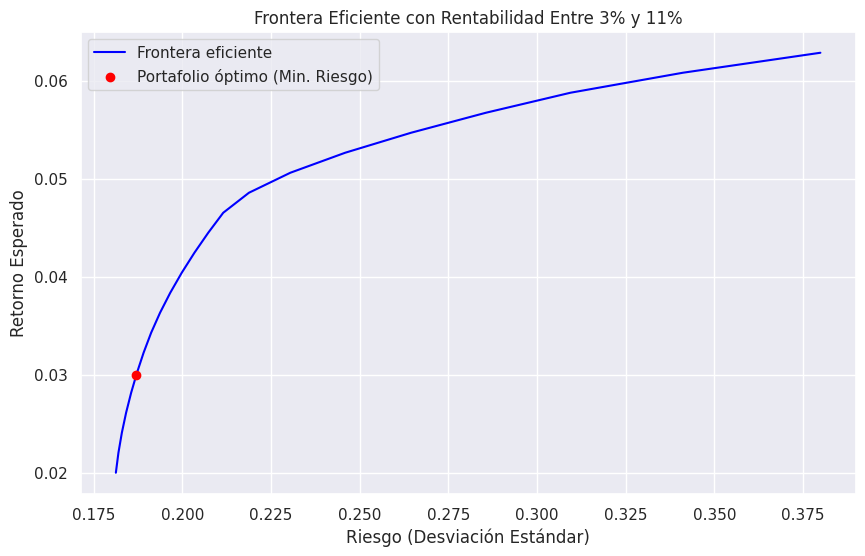

In [247]:
import numpy as np
import cvxpy as cv
import yfinance as yf
import matplotlib.pyplot as plt

# TICKERS DE ACCIONES
tickers = ["RKLB", "SOFI", "PLTR", "WULF", "PTON"]  # LISTA DE LAS ACCIONES QUE SE VAN A ANALIZAR

# DESCARGAMOS EL PRECIO DE CIERRE AJUSTADO DE CADA ACCIÓN
data = yf.download(tickers, start='2019-01-01', end='2024-12-10')['Adj Close']  # DESCARGAMOS LOS PRECIOS DE LAS ACCIONES DESDE YAHOO FINANCE

# AGRUPAMOS LOS DATOS POR MESES Y TOMAMOS EL ÚLTIMO DÍA DEL MES
data = data.resample('M').last()  # AGRUPAMOS LOS DATOS DE LAS ACCIONES POR MES Y TOMAMOS EL ÚLTIMO DÍA DE CADA MES

# CALCULAMOS LOS RETORNOS MENSUALES
returns = data.pct_change().dropna()  # CALCULAMOS LOS RETORNOS MENSUALES COMO EL CAMBIO PORCENTUAL DE LOS PRECIOS

# Aseguramos que returns esté en formato DataFrame
if not isinstance(returns, pd.DataFrame):
    returns = pd.DataFrame(returns)  # NOS ASEGURAMOS DE QUE LOS RETORNOS ESTÉN EN FORMATO TABULAR

# CALCULAMOS LOS RETORNOS PROMEDIO ESPERADOS PARA CADA ACCIÓN
r = np.asarray(np.mean(returns, axis=0))  # CALCULAMOS EL RETORNO PROMEDIO DE CADA ACCIÓN

# CALCULAMOS LA MATRIZ DE COVARIANZAS
C = np.cov(returns.to_numpy().T)  # CALCULAMOS LA MATRIZ DE COVARIANZAS ENTRE LAS ACCIONES

# DEFINIMOS EL NÚMERO DE VARIABLES (ACCIONES)
n = len(tickers)  # DEFINIMOS EL NÚMERO DE ACCIONES EN EL PORTAFOLIO

# DEFINIMOS UNA VARIABLE PARA LAS PONDERACIONES DE CADA ACCIÓN
x = cv.Variable(n)  # VARIABLE PARA LAS PONDERACIONES DE CADA ACCIÓN EN EL PORTAFOLIO

# FIJAMOS LA RENTABILIDAD MÍNIMA Y MÁXIMA EXIGIDA
req_return_min = 0.03  # RENTABILIDAD MÍNIMA DEL 3%  # DEFINIMOS LA RENTABILIDAD MÍNIMA DEL PORTAFOLIO
req_return_max = 0.11  # RENTABILIDAD MÁXIMA DEL 11%  # DEFINIMOS LA RENTABILIDAD MÁXIMA DEL PORTAFOLIO

# DEFINIMOS LA FUNCIÓN DE RETORNO Y RIESGO
ret = r.T @ x  # CALCULAMOS EL RETORNO DEL PORTAFOLIO COMO LA PONDERACIÓN DE CADA ACCIÓN POR SU RETORNO PROMEDIO
risk = cv.quad_form(x, C)  # CALCULAMOS EL RIESGO DEL PORTAFOLIO COMO LA VARIANZA PONDERADA DE LAS ACCIONES

# FORMULAMOS EL PROBLEMA DE OPTIMIZACIÓN
constraints = [
    cv.sum(x) == 1,  # LAS PONDERACIONES DEBE SUMAR 1 (TODO EL CAPITAL DEBE ESTAR INVERTIDO)
    x >= 0,  # LAS PONDERACIONES NO PUEDEN SER NEGATIVAS (NO SE PERMITEN POSICIONES CORTAS)
    ret >= req_return_min,  # RENTABILIDAD MÍNIMA EXIGIDA (3%)
    ret <= req_return_max  # RENTABILIDAD MÁXIMA EXIGIDA (11%)
]
objective = cv.Minimize(risk)  # OBJETIVO: MINIMIZAR EL RIESGO DEL PORTAFOLIO
problem = cv.Problem(objective, constraints)  # DEFINIMOS EL PROBLEMA DE OPTIMIZACIÓN

# RESOLVEMOS EL PROBLEMA
problem.solve()  # RESOLVEMOS EL PROBLEMA DE OPTIMIZACIÓN PARA ENCONTRAR LAS PONDERACIONES ÓPTIMAS

# VALIDAMOS SI SE ENCONTRÓ UNA SOLUCIÓN
if x.value is None:
    raise ValueError("No se pudo encontrar una solución óptima para el problema.")  # VALIDAMOS QUE EL MODELO ENCUENTRE UNA SOLUCIÓN

# MOSTRAMOS LOS RESULTADOS
optimal_weights = x.value  # OBTENEMOS LAS PONDERACIONES ÓPTIMAS DEL PORTAFOLIO
print("\nOptimal Portfolio")
print("----------------------")
for i in range(len(tickers)):
    print(f'Ponderación de {tickers[i]}: {optimal_weights[i] * 100:.2f}%')  # IMPRIMIMOS LAS PONDERACIONES ÓPTIMAS DE CADA ACCIÓN
print("----------------------")
print(f'Retorno esperado: {ret.value * 100:.2f}%')  # IMPRIMIMOS EL RETORNO ESPERADO DEL PORTAFOLIO
print(f'Riesgo esperado: {np.sqrt(risk.value) * 100:.2f}%')  # IMPRIMIMOS EL RIESGO (DESVIACIÓN ESTÁNDAR) DEL PORTAFOLIO

# FUNCIÓN PARA GENERAR LA FRONTERA EFICIENTE
def efficient_frontier(mu, Sigma, return_range):
    risks = []  # LISTA PARA ALMACENAR LOS RIESGOS
    returns = []  # LISTA PARA ALMACENAR LOS RETORNOS
    for target_return in return_range:  # ITERAMOS SOBRE LOS DIFERENTES NIVELES DE RETORNO
        w = cv.Variable(mu.shape[0])  # DEFINIMOS UNA VARIABLE PARA LAS PONDERACIONES DEL PORTAFOLIO
        risk = cv.quad_form(w, Sigma)  # CALCULAMOS EL RIESGO DEL PORTAFOLIO CON LAS NUEVAS PONDERACIONES
        constraints = [cv.sum(w) == 1, w >= 0, mu @ w >= target_return]  # RESTRICCIONES: SUMA DE PONDERACIONES = 1, NO NEGATIVAS, RETORNO MÍNIMO
        problem = cv.Problem(cv.Minimize(risk), constraints)  # PROBLEMA DE OPTIMIZACIÓN
        problem.solve()  # RESOLVEMOS EL PROBLEMA
        if w.value is None:
            continue  # SI NO HAY SOLUCIÓN, CONTINUAMOS
        risks.append(np.sqrt(risk.value))  # AGREGAMOS EL RIESGO OBTENIDO
        returns.append(target_return)  # AGREGAMOS EL RETORNO OBTENIDO
    return risks, returns  # RETORNAMOS LOS RESULTADOS DE RIESGO Y RETORNO

# GENERAMOS DATOS PARA LA FRONTERA EFICIENTE
mu = np.mean(returns.to_numpy(), axis=0)  # LOS PROMEDIOS DE LOS RETORNOS.
Sigma = np.cov(returns.to_numpy().T)  # LA MATRIZ DE COVARIANZAS.
return_range = np.linspace(0.02, 0.12, 50)  # NIVELES DE RETORNO ENTRE EL 2% Y EL 12%.
risks, returns = efficient_frontier(mu, Sigma, return_range)  # GENERAMOS LOS RESULTADOS DE LA FRONTERA EFICIENTE

# GRAFICAMOS LA FRONTERA EFICIENTE
plt.figure(figsize=(10, 6))  # TAMAÑO DE LA FIGURA
plt.plot(risks, returns, label='Frontera eficiente', color='blue')  # DIBUJAMOS LA FRONTERA EFICIENTE
plt.scatter(np.sqrt(risk.value), req_return_min, color='red', label='Portafolio óptimo (Min. Riesgo)', zorder=5)  # DIBUJAMOS EL PUNTO ÓPTIMO
plt.title('Frontera Eficiente con Rentabilidad Entre 3% y 11%')  # TITULO DEL GRAFICO
plt.xlabel('Riesgo (Desviación Estándar)')  # EJE X
plt.ylabel('Retorno Esperado')  # EJE Y
plt.legend()  # LEYENDA DEL GRAFICO
plt.grid(True)  # GRILLA
plt.show()  # MOSTRAMOS EL GRAFICO

# # DIBUJAMOS LA GRÁFICA DE LA FRONTERA EFICIENTE, DESTACANDO EL PORTAFOLIO ÓPTIMO.

SIMULACION DE MONTECARLO DE PORTAFOLIO RECOMENDADO CON VISION DE MERCADO

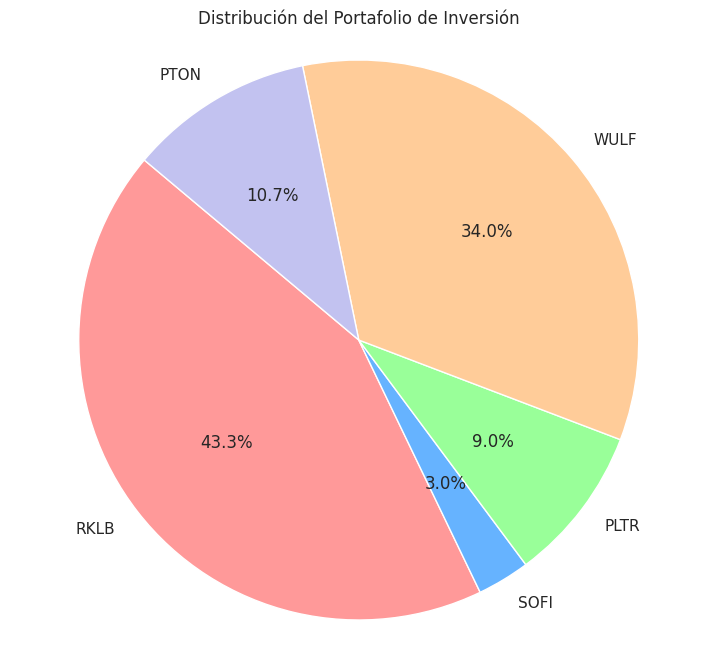

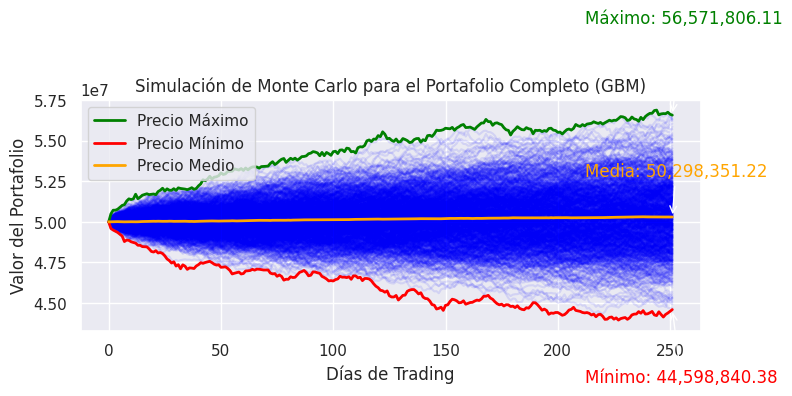

In [248]:
# DATOS DEL PORTAFOLIO OPTIMIZADO (PONDERACIONES)
portfolio_weights = {
    "RKLB": 0.4325,  # Ponderación de RKLB: 43.25%
    "SOFI": 0.0304,  # Ponderación de SOFI: 3.04%
    "PLTR": 0.0903,  # Ponderación de PLTR: 9.03%
    "WULF": 0.3401,  # Ponderación de WULF: 34.01%
    "PTON": 0.1067   # Ponderación de PTON: 10.67%
}
labels = portfolio_weights.keys()
sizes = portfolio_weights.values()

plt.figure(figsize=(9, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99','#ffcc99','#c2c2f0'])

# Título
plt.title('Distribución del Portafolio de Inversión')

# Mostrar gráfico
plt.axis('equal')
plt.show()                                                                         # MOSTRAR EL GRÁFICO
# FILTRAR ACCIONES CON PESOS POSITIVOS
acciones = [accion for accion, peso in portfolio_weights.items() if peso > 0]  # INCLUIR SOLO ACCIONES CON PONDERACIONES MAYORES A 0

# PARÁMETROS DE LA SIMULACIÓN
start_date = "2023-12-10"                                                        # FECHA INICIAL DE LOS DATOS
end_date = "2024-12-10"                                                          # FECHA FINAL DE LOS DATOS
num_simulations = 1000                                                           # NÚMERO DE SIMULACIONES A REALIZAR
simulation_horizon = 252                                                         # NÚMERO DE DÍAS DE TRADING EN UN AÑO
initial_investment = 50000000                                                    # INVERSIÓN INICIAL TOTAL DEL PORTAFOLIO (USD)
confidence_level = 0.99                                                          # NIVEL DE CONFIANZA PARA EL CÁLCULO DEL VaR
delta_t = 1 / simulation_horizon                                                 # INTERVALO DE TIEMPO ENTRE SIMULACIONES

# FIJAR LA SEMILLA PARA RESULTADOS REPRODUCIBLES
np.random.seed(42)  # FIJAR SEMILLA PARA LA GENERACIÓN DE NÚMEROS ALEATORIOS

# DESCARGAR DATOS HISTÓRICOS Y ALINEAR RETORNOS
portfolio_returns = []  # LISTA PARA GUARDAR LOS RETORNOS PONDERADOS
for accion in acciones:  # ITERAR SOBRE CADA ACCIÓN
    data = yf.download(accion, start=start_date, end=end_date, progress=False)  # DESCARGAR DATOS HISTÓRICOS
    data["Returns"] = np.log(data["Close"] / data["Close"].shift(1))            # CALCULAR LOS RETORNOS LOGARÍTMICOS
    data.dropna(inplace=True)                                                   # ELIMINAR FILAS CON DATOS NULOS
    portfolio_returns.append(data["Returns"] * portfolio_weights[accion])       # MULTIPLICAR LOS RETORNOS POR LA PONDERACIÓN DE LA ACCIÓN

# ALINEAR Y SUMAR LOS RETORNOS PONDERADOS
portfolio_returns = pd.concat(portfolio_returns, axis=1).sum(axis=1)  # SUMAR LOS RETORNOS PONDERADOS DE CADA ACCIÓN

# CALCULAR RETORNO Y VOLATILIDAD AGREGADOS DEL PORTAFOLIO
mu_portfolio = np.mean(portfolio_returns)                                       # CALCULAR EL RETORNO PROMEDIO DEL PORTAFOLIO
sigma_portfolio = np.std(portfolio_returns)                                     # CALCULAR LA DESVIACIÓN ESTÁNDAR (VOLATILIDAD) DEL PORTAFOLIO

# GENERAR SIMULACIONES USANDO GBM
portfolio_values = np.zeros((simulation_horizon, num_simulations))              # MATRIZ PARA GUARDAR LOS VALORES DEL PORTAFOLIO
portfolio_values[0] = initial_investment                                        # INICIALIZAR CON LA INVERSIÓN TOTAL

for t in range(1, simulation_horizon):                                          # ITERAR SOBRE CADA DÍA DE SIMULACIÓN
    Z = np.random.normal(0, 1, num_simulations)                                 # GENERAR NÚMEROS ALEATORIOS NORMALES
    portfolio_values[t] = portfolio_values[t - 1] * np.exp(                     # CALCULAR LOS VALORES USANDO EL MODELO GBM
        (mu_portfolio - 0.5 * sigma_portfolio**2) * delta_t +                   # COMPONENTE DRIFT
        sigma_portfolio * np.sqrt(delta_t) * Z                                  # COMPONENTE ESTOCÁSTICO
    )

# GRAFICAR LAS SIMULACIONES
plt.figure(figsize=(8, 3))                                                     # CREAR UNA FIGURA DE TAMAÑO 12x8
for i in range(num_simulations):                                                # ITERAR SOBRE CADA SIMULACIÓN
    plt.plot(portfolio_values[:, i], color='blue', alpha=0.1)                   # GRAFICAR LAS SIMULACIONES EN COLOR AZUL TRANSPARENTE

# CALCULAR VALORES MÁXIMO, MÍNIMO Y MEDIO
portfolio_max = portfolio_values.max(axis=1)                                    # VALOR MÁXIMO POR DÍA
portfolio_min = portfolio_values.min(axis=1)                                    # VALOR MÍNIMO POR DÍA
portfolio_mean = portfolio_values.mean(axis=1)                                  # VALOR PROMEDIO POR DÍA

# GRAFICAR MÁXIMO, MÍNIMO Y MEDIA
plt.plot(portfolio_max, color='green', label='Precio Máximo', linewidth=2)      # GRAFICAR EL MÁXIMO EN VERDE
plt.plot(portfolio_min, color='red', label='Precio Mínimo', linewidth=2)        # GRAFICAR EL MÍNIMO EN ROJO
plt.plot(portfolio_mean, color='orange', label='Precio Medio', linewidth=2)     # GRAFICAR EL PROMEDIO EN NARANJA

# AGREGAR ANOTACIONES PARA EL MÁXIMO, MÍNIMO Y PROMEDIO
plt.annotate(f"Máximo: {portfolio_max[-1]:,.2f}", xy=(simulation_horizon - 1, portfolio_max[-1]),  # ANOTAR EL MÁXIMO
             xytext=(simulation_horizon - 40, portfolio_max[-1] * 1.1),
             arrowprops=dict(facecolor='green', arrowstyle='->'), color='green')
plt.annotate(f"Mínimo: {portfolio_min[-1]:,.2f}", xy=(simulation_horizon - 1, portfolio_min[-1]),  # ANOTAR EL MÍNIMO
             xytext=(simulation_horizon - 40, portfolio_min[-1] * 0.9),
             arrowprops=dict(facecolor='red', arrowstyle='->'), color='red')
plt.annotate(f"Media: {portfolio_mean[-1]:,.2f}", xy=(simulation_horizon - 1, portfolio_mean[-1]),  # ANOTAR EL PROMEDIO
             xytext=(simulation_horizon - 40, portfolio_mean[-1] * 1.05),
             arrowprops=dict(facecolor='orange', arrowstyle='->'), color='orange')

# CONFIGURAR EL GRÁFICO
plt.title("Simulación de Monte Carlo para el Portafolio Completo (GBM)")         # TÍTULO DEL GRÁFICO
plt.xlabel("Días de Trading")                                                   # ETIQUETA DEL EJE X
plt.ylabel("Valor del Portafolio")                                              # ETIQUETA DEL EJE Y
plt.legend()                                                                    # MOSTRAR LA LEYENDA
plt.grid()                                                                      # AGREGAR UNA CUADRÍCULA
plt.show()                                                                      # MOSTRAR EL GRÁFICO
